# English → Hindi Neural Machine Translation
## A Comparative Study of Three Sequence-to-Sequence Architectures

**Author** · Anish
**Corpus** · IIT Bombay English–Hindi Parallel Corpus (`cfilt/iitb-english-hindi`)
**Direction** · English → Hindi (Devanagari output)
**Models** · ① Vanilla LSTM Seq2Seq ② Seq2Seq with Bahdanau Attention ③ Transformer
**Environment** · Google Colab (GPU runtime), PyTorch

---

## 1 · Introduction

This notebook documents a controlled comparison of three neural machine translation
architectures for the English → Hindi language pair, carried out on the IIT Bombay
English–Hindi Parallel Corpus — the standard benchmark resource for this pair.

The question the study sets out to answer is deliberately narrow. When the data budget,
the tokenisation scheme, the optimiser, the early-stopping rule and the decoding
procedure are all held constant, **how much does the architecture itself contribute?**
To answer it, the three most widely used sequence-to-sequence designs are trained
through one identical pipeline and evaluated with the same metrics on the same untouched
test set.

Hindi is a morphologically rich language: case, gender, number, postpositions and verb
conjugations all attach to the stem, so the number of distinct surface forms is very
large. Representing such a language with a word-level vocabulary leaves a substantial
fraction of tokens out-of-vocabulary, and every one of them is emitted as `<unk>`. This
notebook therefore adopts **subword tokenisation**, and Stage 2 measures its effect
directly on the data rather than assuming it.

## 2 · What is used

| Component | Choice |
|---|---|
| Corpus | `cfilt/iitb-english-hindi`, official train / validation / test splits |
| Tokenisation | SentencePiece subword (Unigram), 32,000 pieces per language |
| Model ① | Vanilla LSTM encoder–decoder (Sutskever et al., 2014) |
| Model ② | Bidirectional LSTM encoder with additive Bahdanau attention (Bahdanau et al., 2015) |
| Model ③ | Transformer, 4 encoder and 4 decoder layers (Vaswani et al., 2017) |
| Framework | PyTorch with automatic mixed precision |
| Decoding | Greedy search and beam search |
| Metrics | BLEU (`intl` tokenisation), chrF++, TER |
| Environment | Google Colab, GPU runtime |

## 3 · Expected outcome

A complete run produces the following:

- a **results table** comparing the three models on BLEU, chrF++ and TER, under both
  greedy and beam-search decoding;
- **training and validation loss curves** for each model, with the best epoch marked;
- an analysis of **accuracy as a function of sentence length**, which is where
  attention-based models are expected to separate from a fixed-vector encoder–decoder;
- an **attention alignment heatmap** for the Bahdanau model;
- a **`<unk>` rate comparison** that quantifies the effect of subword tokenisation;

The quantitative outputs — `results.json`, `metrics.csv` and the figures — are written to
disk in a machine-readable form, so that the written report can be authored separately in
LaTeX rather than in Markdown.

On the evidence of the published literature, the attention-based models are expected to
outperform the vanilla encoder–decoder, with the Transformer producing the strongest
scores at a comparable parameter count. The vanilla model is expected to degrade most
sharply as sentence length grows, because it must compress the entire source sentence
into a single fixed-size vector.

---

## 4 · How to run this notebook

1. **Runtime → Change runtime type → T4 GPU.**
2. **Runtime → Run all.** No cell requires manual input; the only interactive cell is the
   demonstration at the end, and it is optional.
3. Collect the artefacts from `<Google Drive>/EnHi_NMT_Study/` when the run finishes.

Everything is written to Drive as it is produced, so a disconnect costs at most one epoch.
Training is resumable: re-running a training cell reloads the existing checkpoint instead
of retraining. Set `CFG.force_retrain = True` to start from scratch.

## 5 · Notebook structure

| Stage | Contents |
|---|---|
| Stage 0 | Setup — dependencies, imports, configuration, helpers |
| Stage 1 | Data — loading, normalisation, filtering, splitting |
| Stage 2 | Tokenisation — word-level baseline and SentencePiece models |
| Stage 3 | Data pipeline — dataset, collation, loaders |
| Stage 4 | Shared components — training loop, decoding, metrics |
| Stage 5 | Models — the three architectures |
| Stage 6 | Training |
| Stage 7 | Evaluation and analysis |
| Stage 8 | Interactive demonstration |
| Stage 9 | Summary and next steps |

---

### What this notebook does

It builds **one** shared data + training + evaluation harness and runs **three**
architectures through it, so that the comparison is genuinely controlled — the only
thing that changes between models is the model.

| Step | What happens | Output |
|---|---|---|
| 1 · Data | load corpus, normalise, filter, split | clean parallel text |
| 2 · Tokenisation | train SentencePiece (subword) models | `sp_en.model`, `sp_hi.model` |
| 3 · Modelling | 3 architectures, identical recipe | checkpoints |
| 4 · Training | AMP, grad-clip, LR schedule, early stop, checkpoint/resume | loss curves |
| 5 · Decoding | greedy **and** beam search | hypotheses |
| 6 · Evaluation | BLEU, chrF++, TER, length buckets, error analysis | `metrics.csv` |

### Expected runtime

The default preset (`balanced`) trains on **100,000** sentence pairs and takes roughly
**60–100 minutes on a free Colab T4**. Everything checkpoints to Google Drive after every
epoch, so a disconnect costs you at most one epoch.

> **First time?** Runtime → Change runtime type → **T4 GPU**, then **Runtime → Run all**.

### Design decisions

Three choices shape everything that follows. Each is stated with its rationale here, and
each is measured later in the notebook rather than assumed.

**1 · Subword tokenisation instead of word-level.**
Hindi is morphologically rich. Case, gender, number, postpositions and verb conjugations
attach to the stem, so a corpus of 100,000 sentences contains a very large number of
distinct surface forms. A word-level vocabulary of a few thousand entries leaves a large
fraction of tokens out-of-vocabulary, and every one of them is emitted as `<unk>`.
SentencePiece subword units with `character_coverage = 1.0` reduce that rate to
essentially zero. Stage 2 measures both rates on the real data.

**2 · A vocabulary of 32,000 pieces per language.**
Large enough to keep common words as single units, while still decomposing rare and unseen
forms into meaningful sub-pieces.

**3 · A maximum sequence length of 128 subword tokens.**
This retains approximately the 97th percentile of the corpus. Subword tokens are shorter
than words, so a budget expressed in subwords is more generous than the same number of
words would be.

### Other design choices

- **Data budget**: 100,000 training pairs, configurable up to 400,000.
- **Model scale**: approximately 23–60 M parameters, with an explicit size comparison.
- **Beam search** in addition to greedy decoding.
- **chrF++ and TER** alongside BLEU. chrF is character-based and therefore far more
  appropriate for a morphologically rich target language than an n-gram metric alone.
- **Automatic mixed precision**, which roughly doubles training throughput on a T4.
- **Learning-rate scheduling and early stopping** on validation loss.
- **Checkpointing and resume**, so a Colab disconnect costs at most one epoch.
- **Deterministic seeding** throughout, so results are reproducible.

### A note on scientific honesty

The corpus is subsampled for tractability, so absolute BLEU will be **lower** than
published results on the full IITB corpus with far larger models. What this notebook
delivers is a **clean, controlled, reproducible relative comparison** of the three
architectures under an identical budget — which is exactly what the architectural
question requires.

### Repository / output layout

Everything is written under `<Drive>/EnHi_NMT_Study/`:

```
EnHi_NMT_Study/
├── data/          cleaned splits + SentencePiece models
├── models/        best checkpoint per model (+ training history JSON)
├── results/       metrics.csv, results.json, per-model hypotheses
├── figures/       loss curves, metric bars, attention heatmap, length analysis
└── logs/          run log
```

`results/metrics.csv` and `results/results.json` are the machine-readable outputs, written
so that a separate LaTeX document can consume them directly.

### Configuration presets

| Preset | Train pairs | Vocab | Epochs | Approx. time (T4) | Use for |
|---|---|---|---|---|---|
| `smoke` | 8 K | 8 K | 2 | ~4 min | verifying the pipeline works |
| **`balanced`** (default) | **100 K** | **32 K** | **12** | **~60–100 min** | the actual results |
| `full` | 400 K | 48 K | 20 | 3–5 h | a stronger run overnight |

Change one line in the configuration cell: `PRESET = "smoke"` for a fast dry-run.

#### 0.1 · Install dependencies

In [1]:
import os, sys, subprocess, importlib

# Reduces allocator fragmentation. The Transformer OOM'd on a 14.6 GB T4 with
# 3.48 GiB reserved-but-unallocated, which is the classic fragmentation signature.
# Must be set before CUDA is initialised, hence before torch is imported (cell 0.2).
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

REQUIRED = ["sentencepiece", "sacrebleu", "datasets", "pandas", "tabulate"]

def _ensure(pkgs):
    missing = []
    for p in pkgs:
        name = p.replace("-", "_")
        try:
            importlib.import_module(name)
        except Exception:
            missing.append(p)
    if missing:
        print("installing:", ", ".join(missing))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=False)
    else:
        print("all dependencies already present")

_ensure(REQUIRED)
import sentencepiece, sacrebleu, datasets, pandas
print("sentencepiece", sentencepiece.__version__)
print("sacrebleu    ", sacrebleu.__version__)
print("datasets     ", datasets.__version__)

installing: sacrebleu
sentencepiece 0.2.2
sacrebleu     2.6.0
datasets      4.8.5


#### 0.2 · Imports

In [2]:
import os, sys, json, math, time, random, shutil, subprocess, warnings, unicodedata, re
from dataclasses import dataclass, asdict, field
from pathlib import Path
from collections import Counter, defaultdict
from typing import List, Dict, Tuple, Optional, Sequence

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

import sentencepiece as spm
import sacrebleu
from datasets import load_dataset

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)
plt.rcParams.update({
    "figure.dpi": 120, "figure.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10,
})
print("torch", torch.__version__)

torch 2.11.0+cu128


#### 0.3 · Configuration

In [3]:
PRESET = "balanced"

PRESETS = {
    "smoke": dict(
        train_subset=8_000, val_subset=1_000, test_subset=1_000,
        sp_vocab_size=8_000, max_tokens=64,
        epochs=2, batch_size=64,
        emb_dim=128, hidden_dim=256, lstm_layers=2,
        d_model=128, nhead=4, enc_layers=2, dec_layers=2, ff_dim=512,
        patience=2, warmup=800, eval_limit=500, beam_eval_limit=200,
    ),
    "balanced": dict(
        train_subset=100_000, val_subset=3_000, test_subset=3_000,
        sp_vocab_size=32_000, max_tokens=128,
        epochs=12, batch_size=128,
        emb_dim=300, hidden_dim=512, lstm_layers=2,
        d_model=512, nhead=8, enc_layers=4, dec_layers=4, ff_dim=2048,
        patience=3, warmup=4000, eval_limit=3000, beam_eval_limit=1000,
    ),
    "full": dict(
        train_subset=400_000, val_subset=5_000, test_subset=5_000,
        sp_vocab_size=48_000, max_tokens=160,
        epochs=20, batch_size=192,
        emb_dim=512, hidden_dim=768, lstm_layers=3,
        d_model=768, nhead=8, enc_layers=6, dec_layers=6, ff_dim=3072,
        patience=4, warmup=8000, eval_limit=5000, beam_eval_limit=2000,
    ),
}

In [4]:
@dataclass
class Config:
    preset: str = PRESET
    seed: int = 42

    dataset_name: str = "cfilt/iitb-english-hindi"
    max_tokens: int = 128
    min_tokens: int = 1
    max_len_ratio: float = 3.0
    train_subset: int = 100_000
    val_subset: int = 3_000
    test_subset: int = 3_000

    sp_vocab_size: int = 32_000
    sp_model_type: str = "unigram"
    sp_char_coverage: float = 1.0

    epochs: int = 12
    batch_size: int = 128
    clip: float = 1.0
    warmup: int = 4000
    patience: int = 3
    min_delta: float = 1e-3
    amp: bool = True
    num_workers: int = 2
    log_every: int = 200

    max_decode_len: int = 128
    beam_size: int = 5
    length_alpha: float = 0.7

    emb_dim: int = 300
    hidden_dim: int = 512
    lstm_layers: int = 2
    attn_dim: int = 512
    d_model: int = 512
    nhead: int = 8
    enc_layers: int = 4
    dec_layers: int = 4
    ff_dim: int = 2048
    dropout: float = 0.3
    dropout_tf: float = 0.1
    tie_embeddings: bool = True

    eval_limit: int = 3000
    beam_eval_limit: int = 1000
    force_retrain: bool = False
    output_dir: str = ""

CFG = Config()
for _k, _v in PRESETS[PRESET].items():
    assert hasattr(CFG, _k), f"unknown preset key: {_k}"
    setattr(CFG, _k, _v)
CFG.preset = PRESET

In [5]:
@dataclass
class TrainSpec:
    name: str
    lr: float
    scheduler: str
    label_smoothing: float = 0.0
    batch_size: int = 128
    epochs: int = 12
    patience: int = 3
    clip: float = 1.0
    warmup: int = 4000
    d_model: int = 512
    micro_batch: int = 0

SPECS = {
    "vanilla": TrainSpec("Vanilla Seq2Seq",      lr=1e-3, scheduler="plateau", label_smoothing=0.0),
    "attention": TrainSpec("Seq2Seq + Bahdanau", lr=1e-3, scheduler="plateau", label_smoothing=0.0),
    "transformer": TrainSpec("Transformer",      lr=1.0,  scheduler="noam",    label_smoothing=0.1),
}
for _s in SPECS.values():
    _s.batch_size = CFG.batch_size
    _s.epochs = CFG.epochs
    _s.patience = CFG.patience
    _s.clip = CFG.clip
    _s.warmup = CFG.warmup
    _s.d_model = CFG.d_model

# The Transformer's output projection is 128 x 127 x 32,000 logits per step, and
# cross_entropy upcasts that to fp32 and keeps the softmax for backward - about
# 3 GB on its own. Splitting each batch into micro-batches of 64 and accumulating
# gradients halves peak memory while keeping the effective batch at 128, so the
# optimisation is unchanged and the three models stay comparable.
SPECS["transformer"].micro_batch = 64

# The Noam peak (lr=1.0, warmup=4000) is ~6.9e-4, the Vaswani default, which assumes
# ~25k tokens per batch. Here a batch is 128 seqs x ~30 subwords = ~4k tokens, so the
# gradients are far noisier. In the first Kaggle run that peak destabilised the model
# exactly as warmup ended: train loss went 7.39 (ep4) -> 10.56 (ep5) and val never
# recovered below the epoch-4 value (6.99), leaving a checkpoint that emitted
# degenerate repetition. lr=0.55 puts the peak at ~3.8e-4 - a 30% margin below the
# last learning rate known to be stable (5.43e-4 at the end of epoch 4) and well
# below the 5.78e-4 at which divergence began. Patience 4 rather than 3 because the
# model was still recovering when the previous run cut it off.
SPECS["transformer"].lr = 0.55
SPECS["transformer"].patience = 4

print(json.dumps(asdict(CFG), indent=2))

{
  "preset": "balanced",
  "seed": 42,
  "dataset_name": "cfilt/iitb-english-hindi",
  "max_tokens": 128,
  "min_tokens": 1,
  "max_len_ratio": 3.0,
  "train_subset": 100000,
  "val_subset": 3000,
  "test_subset": 3000,
  "sp_vocab_size": 32000,
  "sp_model_type": "unigram",
  "sp_char_coverage": 1.0,
  "epochs": 12,
  "batch_size": 128,
  "clip": 1.0,
  "warmup": 4000,
  "patience": 3,
  "min_delta": 0.001,
  "amp": true,
  "num_workers": 2,
  "log_every": 200,
  "max_decode_len": 128,
  "beam_size": 5,
  "length_alpha": 0.7,
  "emb_dim": 300,
  "hidden_dim": 512,
  "lstm_layers": 2,
  "attn_dim": 512,
  "d_model": 512,
  "nhead": 8,
  "enc_layers": 4,
  "dec_layers": 4,
  "ff_dim": 2048,
  "dropout": 0.3,
  "dropout_tf": 0.1,
  "tie_embeddings": true,
  "eval_limit": 3000,
  "beam_eval_limit": 1000,
  "force_retrain": false,
  "output_dir": ""
}


#### 0.4 · Device, output directories, reproducibility

In [6]:
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(CFG.seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"GPU  : {torch.cuda.get_device_name(0)}")
    print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("!! No GPU detected. Runtime -> Change runtime type -> T4 GPU.")
    print("!! The pipeline still runs on CPU but will be very slow.")

IN_COLAB = os.path.exists("/content") and "google.colab" in sys.modules
IN_KAGGLE = os.path.isdir("/kaggle/working")

if IN_KAGGLE:
    ROOT = Path("/kaggle/working/EnHi_NMT_Study")
elif IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    if not DRIVE_ROOT.exists():
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_ROOT = Path("/content/drive/MyDrive")
    ROOT = DRIVE_ROOT / "EnHi_NMT_Study"
    if not str(ROOT).startswith("/content/drive"):
        raise RuntimeError("Drive is not mounted - refusing to write artefacts to ephemeral storage")
else:
    ROOT = Path(CFG.output_dir or (Path.home() / "EnHi_NMT_Study"))

SUBDIRS = ["data", "models", "results", "figures", "reports", "logs"]
for _d in SUBDIRS:
    (ROOT / _d).mkdir(parents=True, exist_ok=True)

D_DATA    = ROOT / "data"
D_MODELS  = ROOT / "models"
D_RESULTS = ROOT / "results"
D_FIGS    = ROOT / "figures"
D_REPORTS = ROOT / "reports"
D_LOGS    = ROOT / "logs"

CFG.output_dir = str(ROOT)
print("\noutput root:", ROOT)

# If a previous run's output is attached as a Kaggle input, seed models/ from it so
# fit() can resume instead of retraining. fit() treats a checkpoint whose history is
# already complete (or stopped_early) as done, so finished models are skipped.
# The mount layout is not guaranteed, so search for any *.pt sitting in a models/ dir.
if IN_KAGGLE and Path("/kaggle/input").is_dir():
    _found = [p for p in Path("/kaggle/input").rglob("*.pt") if p.parent.name == "models"]
    _seeded = 0
    if _found:
        _srcdir = _found[0].parent
        # Vanilla and Bahdanau are kept; the Transformer is deliberately NOT restored so
        # it retrains from scratch under the corrected learning rate.
        _retrain = {"transformer.pt", "transformer_history.json"}
        for _f in sorted(_srcdir.glob("*.pt")) + sorted(_srcdir.glob("*_history.json")):
            if _f.name in _retrain:
                print(f"resume: skipping {_f.name} - will retrain")
                continue
            _dst = D_MODELS / _f.name
            if not _dst.exists():
                shutil.copy2(_f, _dst)
                _seeded += 1
        # The tokenizer must be byte-identical to the one the checkpoints were trained
        # with, or the embedding rows would map to different pieces. SentencePiece
        # shuffles its training input by default, so retraining is not reproducible.
        _sptok = [p for p in Path("/kaggle/input").rglob("sp_en.model") if p.parent.name == "data"]
        if _sptok:
            _spdir = _sptok[0].parent
            for _f in sorted(_spdir.glob("sp_*.model")) + sorted(_spdir.glob("sp_*.vocab")):
                _dst = D_DATA / _f.name
                if not _dst.exists():
                    shutil.copy2(_f, _dst)
                    _seeded += 1
        print(f"resume: found checkpoints in {_srcdir} -> seeded {_seeded} file(s)")
        print("        models/ now:", sorted(p.name for p in D_MODELS.glob("*")))
    else:
        print("resume: no attached checkpoints found under /kaggle/input - training from scratch")


GPU  : Tesla T4
VRAM : 15.6 GB

output root: /kaggle/working/EnHi_NMT_Study
resume: skipping transformer.pt - will retrain
resume: skipping transformer_history.json - will retrain
resume: found checkpoints in /kaggle/input/notebooks/anishdate/en-hi-nmt-architecture-comparison/EnHi_NMT_Study/models -> seeded 8 file(s)
        models/ now: ['attention.pt', 'attention_history.json', 'vanilla.pt', 'vanilla_history.json']


#### 0.5 · Small helpers (logging, IO, parameter counting)

In [7]:
LOG_PATH = D_LOGS / "run.log"

In [8]:
def log(msg: str, echo: bool = True):
    line = f"[{time.strftime('%H:%M:%S')}] {msg}"
    if echo:
        print(line)
    with open(LOG_PATH, "a", encoding="utf-8") as fh:
        fh.write(line + "\n")

In [9]:
def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(obj, fh, indent=2, ensure_ascii=False)
    return path

In [10]:
def load_json(path, default=None):
    path = Path(path)
    if not path.exists():
        return default
    with open(path, "r", encoding="utf-8") as fh:
        return json.load(fh)

In [11]:
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [12]:
def human_int(n: int) -> str:
    return f"{n/1e6:.2f} M" if n >= 1e6 else f"{n/1e3:.1f} K"

In [13]:
def autocast_ctx(device, enabled: bool):
    try:
        return torch.amp.autocast(device_type=device.type, enabled=enabled)
    except Exception:
        return torch.cuda.amp.autocast(enabled=enabled)

In [14]:
def make_scaler(enabled: bool):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)

AMP_ON = bool(CFG.amp and DEVICE.type == "cuda")
print("automatic mixed precision:", "ON" if AMP_ON else "off")

automatic mixed precision: ON


---
## Stage 1 — Data preparation

We use the **IIT Bombay English–Hindi Parallel Corpus**, the standard benchmark for this
language pair. It ships with official `train` / `validation` / `test` splits — we keep the
official test set untouched so the final numbers are comparable to published work.

The pipeline is: **load → normalise → filter → split → subsample**.

#### 1.1 · Load the raw corpus

In [15]:
log(f"loading dataset: {CFG.dataset_name}")
raw = load_dataset(CFG.dataset_name)
print(raw)

def _first(d, keys):
    for k in keys:
        if isinstance(d, dict) and d.get(k):
            return d[k]
    return None

def extract_pairs(split) -> Tuple[List[str], List[str]]:
    ens, his = [], []
    for ex in split:
        tr = ex.get("translation", ex) if isinstance(ex, dict) else {}
        en = _first(tr, ["en", "english", "eng", "source"])
        hi = _first(tr, ["hi", "hindi", "hin", "target"])
        if en and hi:
            ens.append(en)
            his.append(hi)
    return ens, his

SPLITS = {}
for name in raw.keys():
    e, h = extract_pairs(raw[name])
    SPLITS[name] = (e, h)
    log(f"  split '{name}': {len(e):,} pairs")

if "train" not in SPLITS:
    raise RuntimeError("dataset has no 'train' split - cannot continue")
if "validation" not in SPLITS:
    SPLITS["validation"] = ([], [])
if "test" not in SPLITS:
    raise RuntimeError("dataset has no 'test' split - cannot continue")

print()
for k, (e, h) in SPLITS.items():
    print(f"{k:12s} {len(e):>10,} pairs")

[10:07:37] loading dataset: cfilt/iitb-english-hindi


README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  190MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.7kB            

... (3 outputs left out)

Generating train split:   0%|          | 0/1659083 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/520 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2507 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['translation'],
        num_rows: 1659083
    })
    validation: Dataset({
        features: ['translation'],
        num_rows: 520
    })
    test: Dataset({
        features: ['translation'],
        num_rows: 2507
    })
})
[10:08:20]   split 'train': 1,652,981 pairs
[10:08:20]   split 'validation': 520 pairs
[10:08:20]   split 'test': 2,507 pairs

train         1,652,981 pairs
validation          520 pairs
test              2,507 pairs


#### 1.2 · Exploratory analysis — how long are the sentences?

In [16]:
def token_lengths(texts: Sequence[str]) -> np.ndarray:
    return np.array([len(t.split()) for t in texts], dtype=np.int64)

en_len = token_lengths(SPLITS["train"][0])
hi_len = token_lengths(SPLITS["train"][1])

      English (words)  Hindi (words)
mean             13.1           14.1
p50               9.0            9.0
p90              30.0           33.0
p95              40.0           44.0
p99              68.0           76.0
max            1917.0         1380.0


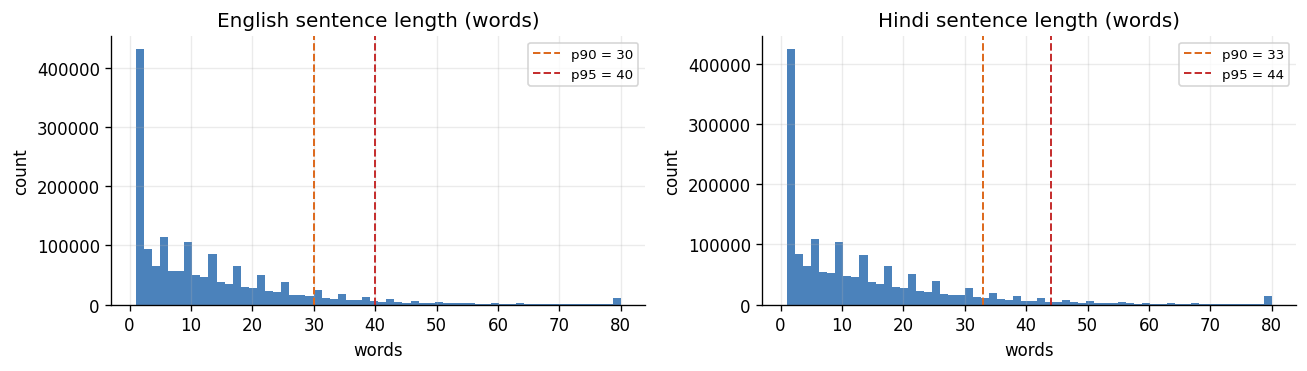

word-length cut at p90 (   32 words) keeps  88.7% of pairs
word-length cut at p95 (   42 words) keeps  94.0% of pairs
word-length cut at p97 (   50 words) keeps  96.2% of pairs
word-length cut at p99 (   72 words) keeps  98.7% of pairs

NOTE: the final cut is applied on SUBWORD tokens (cell 2.4), which are
      shorter than words - so the token budget below is deliberately generous.


In [17]:
def pct(arr, q): return float(np.percentile(arr, q))

stats = pd.DataFrame({
    "English (words)": [float(en_len.mean()), pct(en_len, 50), pct(en_len, 90),
                        pct(en_len, 95), pct(en_len, 99), float(en_len.max())],
    "Hindi (words)":   [float(hi_len.mean()), pct(hi_len, 50), pct(hi_len, 90),
                        pct(hi_len, 95), pct(hi_len, 99), float(hi_len.max())],
}, index=["mean", "p50", "p90", "p95", "p99", "max"]).round(1)
print(stats.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, arr, label in zip(axes, [en_len, hi_len], ["English", "Hindi"]):
    ax.hist(np.clip(arr, 0, 80), bins=60, color="#2b6cb0", alpha=0.85)
    ax.set_title(f"{label} sentence length (words)")
    ax.set_xlabel("words"); ax.set_ylabel("count")
    for q, c in [(90, "#dd6b20"), (95, "#c53030")]:
        ax.axvline(pct(arr, q), color=c, ls="--", lw=1.2, label=f"p{q} = {pct(arr,q):.0f}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(D_FIGS / "01_length_distribution.png", bbox_inches="tight")
plt.show()

for q in (90, 95, 97, 99):
    lim = pct(np.concatenate([en_len, hi_len]), q)
    keep = float(((en_len <= lim) & (hi_len <= lim)).mean() * 100)
    print(f"word-length cut at p{q:>2} ({lim:5.0f} words) keeps {keep:5.1f}% of pairs")

print()
print("NOTE: the final cut is applied on SUBWORD tokens (cell 2.4), which are")
print("      shorter than words - so the token budget below is deliberately generous.")

#### 1.3 · Normalise, deduplicate and filter

In [18]:
def normalise_en(s: str) -> str:
    s = unicodedata.normalize("NFKC", s)
    s = s.replace("\u200b", " ").replace("\xa0", " ").replace("\ufeff", "")
    s = re.sub(r"\s+", " ", s)
    return s.strip()

In [19]:
def normalise_hi(s: str) -> str:
    s = unicodedata.normalize("NFC", s)
    s = s.replace("\u200b", " ").replace("\xa0", " ").replace("\ufeff", "")
    s = re.sub(r"\s+", " ", s)
    return s.strip()

_DEV = re.compile(r"[\u0900-\u097F]")

In [20]:
def is_valid(en: str, hi: str) -> bool:
    if not en or not hi:
        return False
    if en.lower() == hi.lower():
        return False
    if len(en) < 2 or len(hi) < 2:
        return False
    if not _DEV.search(hi):
        return False
    ne, nh = len(en.split()), len(hi.split())
    if ne == 0 or nh == 0:
        return False
    if max(ne, nh) / min(ne, nh) > CFG.max_len_ratio:
        return False
    return True

In [21]:
def clean_split(ens: List[str], his: List[str], label: str):
    before = len(ens)
    seen = set()
    out_en, out_hi = [], []
    for e, h in zip(ens, his):
        e, h = normalise_en(e), normalise_hi(h)
        if not is_valid(e, h):
            continue
        key = (e, h)
        if key in seen:
            continue
        seen.add(key)
        out_en.append(e)
        out_hi.append(h)
    log(f"  {label}: {before:,} -> {len(out_en):,} pairs "
        f"({100*len(out_en)/max(before,1):.1f}% kept)")
    return out_en, out_hi

log("cleaning splits ...")
CLEAN = {}
for name, (e, h) in SPLITS.items():
    CLEAN[name] = clean_split(e, h, name)

tr_en, tr_hi = CLEAN["train"]
va_en, va_hi = CLEAN["validation"]
te_en, te_hi = CLEAN["test"]
print()
print(f"train {len(tr_en):,} | validation {len(va_en):,} | test {len(te_en):,}")

[10:08:25] cleaning splits ...
[10:08:59]   train: 1,652,981 -> 1,377,338 pairs (83.3% kept)
[10:08:59]   validation: 520 -> 520 pairs (100.0% kept)
[10:08:59]   test: 2,507 -> 2,505 pairs (99.9% kept)

train 1,377,338 | validation 520 | test 2,505


#### 1.4 · Deterministic subsampling (train / validation / test)

In [22]:
rng = np.random.RandomState(CFG.seed)

In [23]:
def subsample(en, hi, n, rng):
    if n is None or n >= len(en):
        return list(en), list(hi)
    idx = rng.permutation(len(en))[:n]
    return [en[i] for i in idx], [hi[i] for i in idx]

n_train = min(CFG.train_subset, len(tr_en))
perm = rng.permutation(len(tr_en))
train_idx = perm[:n_train]

n_extra_val = max(0, CFG.val_subset - len(va_en))
extra_val_idx = perm[n_train:n_train + n_extra_val]

TRAIN_EN = [tr_en[i] for i in train_idx]
TRAIN_HI = [tr_hi[i] for i in train_idx]
VAL_EN   = list(va_en) + [tr_en[i] for i in extra_val_idx]
VAL_HI   = list(va_hi) + [tr_hi[i] for i in extra_val_idx]

TEST_EN, TEST_HI = subsample(te_en, te_hi, CFG.test_subset, np.random.RandomState(CFG.seed + 1))

DATA_SUMMARY = {
    "preset": CFG.preset,
    "train_pairs": len(TRAIN_EN),
    "val_pairs": len(VAL_EN),
    "test_pairs": len(TEST_EN),
    "official_test_pairs": len(te_en),
    "seed": CFG.seed,
}
save_json(DATA_SUMMARY, D_DATA / "data_summary.json")

print(pd.DataFrame({
    "split": ["train", "validation", "test"],
    "pairs": [len(TRAIN_EN), len(VAL_EN), len(TEST_EN)],
    "source": ["official train (subsampled)",
               f"official val ({len(va_en)}) + {n_extra_val} held-out train",
               f"official test (of {len(te_en):,})"],
}).to_string(index=False))

print("\nExample pair:")
i = rng.randint(len(TRAIN_EN))
print("  EN:", TRAIN_EN[i])
print("  HI:", TRAIN_HI[i])

     split  pairs                                   source
     train 100000              official train (subsampled)
validation   3000 official val (520) + 2480 held-out train
      test   2505                 official test (of 2,505)

Example pair:
  EN: Voluntary
  HI: ऐच्छिक


---
## Stage 2 — Tokenisation

**This is the design decision that matters most for this language pair.**

At word level, a Hindi corpus of 100 K sentences has an enormous number of distinct surface
forms (case, gender, number, postpositions and verb conjugations all attach to the stem).
A word-level vocabulary of a few thousand entries therefore leaves a huge fraction of
tokens out-of-vocabulary — and every one of them is emitted as `<unk>`.

The cell below *measures* that rate on the actual data. The cell after it trains the
subword models that remove it. Both numbers are reported, so the improvement is documented
with evidence rather than asserted.

#### 2.1 · Baseline: how bad is word-level tokenisation?

In [24]:
def word_oov_rate(train_texts, eval_texts, min_freq=2):
    counts = Counter()
    for t in train_texts:
        counts.update(t.split())
    vocab = {w for w, c in counts.items() if c >= min_freq}
    total = oov = 0
    for t in eval_texts:
        ws = t.split()
        total += len(ws)
        oov += sum(1 for w in ws if w not in vocab)
    return oov / max(total, 1), len(vocab)

en_oov, en_vocab = word_oov_rate(TRAIN_EN, TEST_EN)
hi_oov, hi_vocab = word_oov_rate(TRAIN_HI, TEST_HI)

print(f"Word-level vocabulary (min_freq >= 2, trained on the {len(TRAIN_EN):,} training pairs)")
print(f"  English : vocab {en_vocab:>8,}   OOV on test = {en_oov*100:6.2f}%")
print(f"  Hindi   : vocab {hi_vocab:>8,}   OOV on test = {hi_oov*100:6.2f}%")
print()
print("Every OOV token is an <unk> at inference time. Subword tokenisation")
print("(next cell) is what removes that failure mode.")

WORD_BASELINE = {"en_vocab": en_vocab, "hi_vocab": hi_vocab,
                 "en_oov": en_oov, "hi_oov": hi_oov}
save_json(WORD_BASELINE, D_RESULTS / "word_level_baseline.json")

Word-level vocabulary (min_freq >= 2, trained on the 100,000 training pairs)
  English : vocab   49,955   OOV on test =  11.97%
  Hindi   : vocab   43,774   OOV on test =   8.85%

Every OOV token is an <unk> at inference time. Subword tokenisation
(next cell) is what removes that failure mode.


PosixPath('/kaggle/working/EnHi_NMT_Study/results/word_level_baseline.json')

#### 2.2 · Train SentencePiece (subword) models

In [25]:
def train_sentencepiece(sentences: List[str], prefix: Path, vocab_size: int, model_type: str) -> Path:
    corpus = Path(str(prefix) + ".corpus.txt")
    with open(corpus, "w", encoding="utf-8") as fh:
        for s in sentences:
            fh.write(s.replace("\n", " ") + "\n")

    spm.SentencePieceTrainer.train(
        input=str(corpus),
        model_prefix=str(prefix),
        vocab_size=vocab_size,
        model_type=model_type,
        character_coverage=CFG.sp_char_coverage,
        pad_id=0, unk_id=1, bos_id=2, eos_id=3,
        pad_piece="<pad>", unk_piece="<unk>", bos_piece="<s>", eos_piece="</s>",
        split_digits=True,
        byte_fallback=False,
        hard_vocab_limit=False,
        max_sentence_length=8192,
        num_threads=max(1, (os.cpu_count() or 2)),
        train_extremely_large_corpus=False,
    )
    corpus.unlink(missing_ok=True)
    return Path(str(prefix) + ".model")

def ensure_sentencepiece(sentences: List[str], prefix: Path, label: str) -> Path:
    existing = Path(str(prefix) + ".model")
    if existing.exists():
        log(f"reusing existing {label} SentencePiece model ({existing.name})")
        return existing
    log(f"training {label} SentencePiece model (vocab {CFG.sp_vocab_size:,}) ...")
    t0 = time.time()
    p = train_sentencepiece(sentences, prefix, CFG.sp_vocab_size, CFG.sp_model_type)
    log(f"  done in {time.time()-t0:.1f}s")
    return p

SP_EN_PATH = ensure_sentencepiece(TRAIN_EN, D_DATA / "sp_en", "English")
SP_HI_PATH = ensure_sentencepiece(TRAIN_HI, D_DATA / "sp_hi", "Hindi")

print("\nEnglish model:", SP_EN_PATH)
print("Hindi   model:", SP_HI_PATH)

[10:09:00] reusing existing English SentencePiece model (sp_en.model)
[10:09:00] reusing existing Hindi SentencePiece model (sp_hi.model)

English model: /kaggle/working/EnHi_NMT_Study/data/sp_en.model
Hindi   model: /kaggle/working/EnHi_NMT_Study/data/sp_hi.model


#### 2.3 · Tokenizer wrapper + measured <unk> rate

In [26]:
class SPTokenizer:

    def __init__(self, model_path: Path, name: str = ""):
        self.name = name
        self.sp = spm.SentencePieceProcessor(model_file=str(model_path))
        self.pad_id = self.sp.pad_id()
        self.unk_id = self.sp.unk_id()
        self.bos_id = self.sp.bos_id()
        self.eos_id = self.sp.eos_id()
        self.vocab_size = self.sp.get_piece_size()

    def encode(self, text: str, add_bos: bool = True, add_eos: bool = True) -> List[int]:
        ids = self.sp.encode(text, out_type=int)
        if add_bos:
            ids = [self.bos_id] + ids
        if add_eos:
            ids = ids + [self.eos_id]
        return ids

    def encode_plain(self, text: str) -> List[int]:
        return self.sp.encode(text, out_type=int)

    def decode(self, ids: Sequence[int]) -> str:
        specials = {self.pad_id, self.bos_id, self.eos_id}
        keep = [int(i) for i in ids if int(i) not in specials]
        return self.sp.decode(keep)

    def pieces(self, text: str) -> List[str]:
        return self.sp.encode(text, out_type=str)

    def unk_rate(self, texts: Sequence[str], limit: int = 5000) -> Tuple[float, float]:
        total = unk = sents_with_unk = 0
        for t in texts[:limit]:
            ids = self.encode_plain(t)
            total += len(ids)
            n_unk = sum(1 for i in ids if i == self.unk_id)
            unk += n_unk
            sents_with_unk += int(n_unk > 0)
        n = max(1, min(limit, len(texts)))
        return unk / max(total, 1), sents_with_unk / n

SRC_TOK = SPTokenizer(SP_EN_PATH, "en")
TGT_TOK = SPTokenizer(SP_HI_PATH, "hi")

print(f"English vocab: {SRC_TOK.vocab_size:,}   "
      f"(pad={SRC_TOK.pad_id} unk={SRC_TOK.unk_id} bos={SRC_TOK.bos_id} eos={SRC_TOK.eos_id})")
print(f"Hindi   vocab: {TGT_TOK.vocab_size:,}   "
      f"(pad={TGT_TOK.pad_id} unk={TGT_TOK.unk_id} bos={TGT_TOK.bos_id} eos={TGT_TOK.eos_id})")

en_unk, en_unk_s = SRC_TOK.unk_rate(TEST_EN)
hi_unk, hi_unk_s = TGT_TOK.unk_rate(TEST_HI)

print()
print("=" * 68)
print("  <unk> RATE ON THE TEST SET  (subword vs word-level)")
print("=" * 68)
print(f"  {'':<10}{'token-level <unk>':>22}{'sentences with <unk>':>24}")
print(f"  {'English':<10}{en_unk*100:>21.3f}%{en_unk_s*100:>23.1f}%")
print(f"  {'Hindi':<10}{hi_unk*100:>21.3f}%{hi_unk_s*100:>23.1f}%")
print("-" * 68)
print(f"  word-level baseline (Hindi OOV): {hi_oov*100:.2f}%  ->  subword: {hi_unk*100:.3f}%")
print(f"  reduction: {(1 - hi_unk/max(hi_oov,1e-9))*100:.1f}%")
print("=" * 68)

TOKENIZER_SUMMARY = {
    "src_vocab": SRC_TOK.vocab_size,
    "tgt_vocab": TGT_TOK.vocab_size,
    "src_unk_rate": en_unk, "tgt_unk_rate": hi_unk,
    "src_sent_unk": en_unk_s, "tgt_sent_unk": hi_unk_s,
    "word_baseline": WORD_BASELINE,
}
save_json(TOKENIZER_SUMMARY, D_RESULTS / "tokenizer_summary.json")

demo = TRAIN_EN[0]
print("\nExample segmentation:")
print("  raw      :", demo)
print("  pieces   :", " | ".join(SRC_TOK.pieces(demo)))
print("  roundtrip:", SRC_TOK.decode(SRC_TOK.encode_plain(demo)))
print("  length   :", len(demo.split()), "words ->", len(SRC_TOK.pieces(demo)), "subwords")

English vocab: 32,000   (pad=0 unk=1 bos=2 eos=3)
Hindi   vocab: 32,000   (pad=0 unk=1 bos=2 eos=3)

  <unk> RATE ON THE TEST SET  (subword vs word-level)
                 token-level <unk>    sentences with <unk>
  English                   0.000%                    0.0%
  Hindi                     0.001%                    0.0%
--------------------------------------------------------------------
  word-level baseline (Hindi OOV): 8.85%  ->  subword: 0.001%
  reduction: 100.0%

Example segmentation:
  raw      : unwholesomeness
  pieces   : ▁unwholesome | ness
  roundtrip: unwholesomeness
  length   : 1 words -> 2 subwords


---
## Stage 3 — Data pipeline

Sentences are encoded to subword ids with an explicit `<s> … </s>` frame. The collate
function pads to the longest sequence **in the batch** (not to a global maximum), which
saves a lot of wasted compute.

One important detail: the **length filter is applied on subword tokens**, so the
`max_tokens` budget in the config is the true sequence-length cap.

#### 3.1 · Parallel dataset + collate + loaders

In [27]:
class ParallelDataset(Dataset):

    def __init__(self, src_texts, tgt_texts, src_tok, tgt_tok, max_tokens: int):
        self.src_tok = src_tok
        self.tgt_tok = tgt_tok
        self.max_tokens = max_tokens
        self.pairs: List[Tuple[List[int], List[int]]] = []
        dropped = 0
        for s, t in zip(src_texts, tgt_texts):
            si = src_tok.encode(s)
            ti = tgt_tok.encode(t)
            if len(si) > max_tokens or len(ti) > max_tokens:
                dropped += 1
                continue
            self.pairs.append((si, ti))
        self.dropped = dropped

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        return self.pairs[i]

In [28]:
def make_collate(pad_id: int):
    def collate(batch):
        src, tgt = zip(*batch)
        src_len = torch.tensor([len(s) for s in src], dtype=torch.long)
        tgt_len = torch.tensor([len(t) for t in tgt], dtype=torch.long)
        src = pad_sequence([torch.tensor(s, dtype=torch.long) for s in src],
                           batch_first=True, padding_value=pad_id)
        tgt = pad_sequence([torch.tensor(t, dtype=torch.long) for t in tgt],
                           batch_first=True, padding_value=pad_id)
        return src, src_len, tgt, tgt_len
    return collate

PAD_ID = SRC_TOK.pad_id
BOS_ID = SRC_TOK.bos_id
EOS_ID = SRC_TOK.eos_id

log("encoding splits ...")
train_ds = ParallelDataset(TRAIN_EN, TRAIN_HI, SRC_TOK, TGT_TOK, CFG.max_tokens)
val_ds   = ParallelDataset(VAL_EN,   VAL_HI,   SRC_TOK, TGT_TOK, CFG.max_tokens)
test_ds  = ParallelDataset(TEST_EN,  TEST_HI,  SRC_TOK, TGT_TOK, CFG.max_tokens)

log(f"  train {len(train_ds):,} (dropped {train_ds.dropped:,} over-length)")
log(f"  val   {len(val_ds):,} (dropped {val_ds.dropped:,})")
log(f"  test  {len(test_ds):,} (dropped {test_ds.dropped:,})")

COLLATE = make_collate(PAD_ID)
_loader_kw = dict(num_workers=CFG.num_workers, collate_fn=COLLATE,
                  pin_memory=(DEVICE.type == "cuda"))
if CFG.num_workers > 0:
    _loader_kw["persistent_workers"] = True

train_loader = DataLoader(train_ds, batch_size=CFG.batch_size, shuffle=True, drop_last=True, **_loader_kw)
val_loader   = DataLoader(val_ds,   batch_size=CFG.batch_size, shuffle=False, **_loader_kw)
test_loader  = DataLoader(test_ds,  batch_size=CFG.batch_size, shuffle=False, **_loader_kw)

DATA_SUMMARY.update({"train_encoded": len(train_ds), "val_encoded": len(val_ds), "test_encoded": len(test_ds)})
save_json(DATA_SUMMARY, D_DATA / "data_summary.json")

[10:09:01] encoding splits ...
[10:09:04]   train 99,561 (dropped 439 over-length)
[10:09:04]   val   2,992 (dropped 8)
[10:09:04]   test  2,505 (dropped 0)


PosixPath('/kaggle/working/EnHi_NMT_Study/data/data_summary.json')

#### 3.2 · Sanity check — decode a real batch

In [29]:
src, src_len, tgt, tgt_len = next(iter(train_loader))
print("src      ", tuple(src.shape), src.dtype)
print("src_len  ", tuple(src_len.shape), "min/max:", int(src_len.min()), int(src_len.max()))
print("tgt      ", tuple(tgt.shape))
print()

for i in range(3):
    s = src[i, :src_len[i]].tolist()
    t = tgt[i, :tgt_len[i]].tolist()
    print(f"[{i}] EN ({len(s):>3} tok): {SRC_TOK.decode(s)}")
    print(f"[{i}] HI ({len(t):>3} tok): {TGT_TOK.decode(t)}")
    print()

assert src.shape[1] == int(src_len.max()), "padding width must equal the batch max length"
assert tgt.shape[1] == int(tgt_len.max()), "target padding width must match target lengths"
assert tgt[:, 0].eq(BOS_ID).all(),         "every target must start with <s>"
assert int(src_len.min()) >= 2,            "sequences must have at least <s> and </s>"
assert int(src_len.max()) <= CFG.max_tokens, "no sequence may exceed max_tokens"
assert PAD_ID == 0, "pad id must be 0 for the ignore_index used in the loss"
print("all batch sanity checks passed")

src       (128, 99) torch.int64
src_len   (128,) min/max: 3 99
tgt       (128, 99)

[0] EN ( 41 tok): They will say, ‘Woe to us! Who raised us from our place of sleep? ’ ‘This is what the All - beneficent had promised, and the apostles had spoken the truth! ’
[0] HI ( 34 tok): कहेंगे, "ऐ अफ़सोस हम पर! किसने हमें सोते से जगा दिया? यह वही चीज़ है जिसका रहमान ने वादा किया था और रसूलों ने सच कहा था।"

[1] EN ( 55 tok): To Allah belongs all that is in the heavens and earth. We have charged those who were given the Book before you and you to fear Allah. If you disbelieve, to Allah belongs all that is in the heavens and the earth. Allah is Rich, the Praised.
[1] HI ( 71 tok): आकाशों और धरती में जो कुछ है, सब अल्लाह ही का है। तुमसे पहले जिन्हें किताब दी गई थी, उन्हें और तुम्हें भी हमने ताकीद की है कि "अल्लाह का डर रखो।" यदि तुम इनकार करते हो, तो इससे क्या होने का? आकाशों और धरती में जो कुछ है, सब अल्लाह ही का रहेगा। अल्लाह तो निस्पृह, प्रशंसनीय है

[2] EN ( 16 tok): Incompatible Actions "% 1" 

---
## Stage 4 — Shared training, decoding and evaluation components

Everything below is model-agnostic. Each architecture only has to implement three things:

```python
encode(src, src_len)                      -> (memory, memory_mask, state)
decode_step(prefix_ids, state, memory, memory_mask) -> (logits, new_state)
forward(src, src_len, tgt_in)             -> logits            # teacher forcing
```

Because the harness is shared, greedy search, beam search, the training loop, the metric
computation and the checkpoint format are **byte-identical across the three models**. That
is what makes the comparison controlled.

#### 4.1 · Training utilities (AMP, grad-clip, LR schedules, early stop, resume)

In [30]:
def noam_lambda(step: int, d_model: int, warmup: int, factor: float = 1.0) -> float:
    step = max(step, 1)
    return factor * (d_model ** -0.5) * min(step ** -0.5, step * warmup ** -1.5)

In [31]:
def build_optimizer_scheduler(model, spec: TrainSpec):
    opt = torch.optim.Adam(model.parameters(), lr=spec.lr, betas=(0.9, 0.98), eps=1e-9)
    if spec.scheduler == "noam":
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda s: noam_lambda(s, spec.d_model, spec.warmup))
        return opt, sched, False
    if spec.scheduler == "plateau":
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
            opt, mode="min", factor=0.5, patience=1, min_lr=1e-5)
        return opt, sched, True
    return opt, None, False

In [32]:
def train_one_epoch(model, loader, optimizer, scheduler, scaler, device,
                    pad_id, spec: TrainSpec, epoch: int, log_every: int = 200):
    model.train()
    total_loss = total_tokens = 0
    micro = int(getattr(spec, "micro_batch", 0) or 0)
    t0 = time.time()
    for step, (src, src_len, tgt, tgt_len) in enumerate(loader, start=1):
        src = src.to(device, non_blocking=True)
        src_len = src_len.to(device, non_blocking=True)
        tgt = tgt.to(device, non_blocking=True)

        tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]
        bs = src.size(0)
        n_tok = bs * max(int(tgt.size(1)) - 1, 1)
        chunk = micro if 0 < micro < bs else bs
        bounds = [(lo, min(lo + chunk, bs)) for lo in range(0, bs, chunk)]
        n_valid = [int((tgt_out[lo:hi] != pad_id).sum()) for lo, hi in bounds]
        total_valid = max(sum(n_valid), 1)

        optimizer.zero_grad(set_to_none=True)
        step_loss_sum = 0.0
        for (lo, hi), nv in zip(bounds, n_valid):
            if hi <= lo:
                continue
            s_b, sl_b = src[lo:hi], src_len[lo:hi]
            ti_b, to_b = tgt_in[lo:hi], tgt_out[lo:hi]
            with autocast_ctx(device, AMP_ON):
                logits = model(s_b, sl_b, ti_b)
                loss = F.cross_entropy(
                    logits.reshape(-1, logits.size(-1)),
                    to_b.reshape(-1),
                    ignore_index=pad_id,
                    label_smoothing=spec.label_smoothing,
                )
                scaled = loss * (nv / total_valid)
            scaler.scale(scaled).backward()
            step_loss_sum += float(loss.detach()) * int(to_b.numel())
            del logits, loss, scaled
        del src, src_len, tgt, tgt_in, tgt_out

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), spec.clip)
        scaler.step(optimizer)
        scaler.update()

        if scheduler is not None and not spec.scheduler == "plateau":
            scheduler.step()

        total_loss += step_loss_sum
        total_tokens += n_tok

        if log_every and step % log_every == 0:
            ppl = math.exp(min(20.0, total_loss / max(total_tokens, 1)))
            lr_now = optimizer.param_groups[0]["lr"]
            log(f"    ep{epoch:>2} step {step:>5}/{len(loader)}  "
                f"loss {total_loss/max(total_tokens,1):.4f}  ppl {ppl:7.2f}  lr {lr_now:.2e}", echo=True)

    return total_loss / max(total_tokens, 1), time.time() - t0


In [33]:
@torch.no_grad()
def evaluate_loss(model, loader, device, pad_id, spec: TrainSpec):
    model.eval()
    total_loss = total_tokens = 0
    for src, src_len, tgt, tgt_len in loader:
        src = src.to(device, non_blocking=True)
        src_len = src_len.to(device, non_blocking=True)
        tgt = tgt.to(device, non_blocking=True)
        tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]
        with autocast_ctx(device, AMP_ON):
            logits = model(src, src_len, tgt_in)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                   tgt_out.reshape(-1),
                                   ignore_index=pad_id,
                                   label_smoothing=spec.label_smoothing)
        n_tok = int(tgt_out.numel())
        total_loss += float(loss) * n_tok
        total_tokens += n_tok
    return total_loss / max(total_tokens, 1)

In [34]:
def fit(model, train_loader, val_loader, spec: TrainSpec, key: str, device, pad_id):
    ckpt_path = D_MODELS / f"{key}.pt"
    hist_path = D_MODELS / f"{key}_history.json"

    history = {"train_loss": [], "val_loss": [], "lr": [], "epoch_seconds": [],
               "best_epoch": 0, "best_val_loss": float("inf"), "stopped_early": False}
    start_epoch = 1

    if ckpt_path.exists() and not CFG.force_retrain:
        blob = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(blob["model"])
        history = load_json(hist_path, {}) or history
        done = len(history.get("val_loss", []))
        if done >= spec.epochs or history.get("stopped_early"):
            log(f"[{spec.name}] training complete: {done} epochs, "
                f"best epoch {blob.get('epoch')}, val loss {blob.get('val_loss'):.4f}")
            return model, history
        start_epoch = done + 1
        log(f"[{spec.name}] resuming at epoch {start_epoch}/{spec.epochs} from checkpoint "
            f"(best val loss {blob.get('val_loss'):.4f})")

    optimizer, scheduler, sched_with_loss = build_optimizer_scheduler(model, spec)
    scaler = make_scaler(AMP_ON)

    best_val = history.get("best_val_loss", float("inf"))
    bad_epochs = 0

    log(f"[{spec.name}] training: {count_parameters(model)/1e6:.2f} M params, "
        f"{spec.epochs} epochs max, lr={spec.lr}, scheduler={spec.scheduler}, "
        f"label_smoothing={spec.label_smoothing}")

    for epoch in range(start_epoch, spec.epochs + 1):
        tr_loss, secs = train_one_epoch(model, train_loader, optimizer, scheduler,
                                        scaler, device, pad_id, spec, epoch, CFG.log_every)
        va_loss = evaluate_loss(model, val_loader, device, pad_id, spec)

        if scheduler is not None and sched_with_loss:
            scheduler.step(va_loss)
        lr_now = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["lr"].append(lr_now)
        history["epoch_seconds"].append(secs)

        improved = va_loss < best_val - CFG.min_delta
        if improved:
            best_val, bad_epochs = va_loss, 0
            history["best_epoch"] = epoch
            history["best_val_loss"] = va_loss
            torch.save({
                "model": model.state_dict(),
                "config": asdict(CFG),
                "spec": asdict(spec),
                "epoch": epoch,
                "val_loss": va_loss,
                "params": count_parameters(model),
            }, ckpt_path)
            flag = "  *best*"
        else:
            bad_epochs += 1
            flag = f"  (no improve {bad_epochs}/{spec.patience})"

        log(f"[{spec.name}] epoch {epoch:>2}/{spec.epochs}  "
            f"train {tr_loss:.4f}  val {va_loss:.4f}  ppl {math.exp(min(20, va_loss)):8.2f}  "
            f"lr {lr_now:.2e}  {secs:5.1f}s{flag}")

        save_json(history, hist_path)
        if bad_epochs >= spec.patience:
            history["stopped_early"] = True
            save_json(history, hist_path)
            log(f"[{spec.name}] early stopping at epoch {epoch}")
            break

    if ckpt_path.exists():
        blob = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(blob["model"])
        log(f"[{spec.name}] restored best checkpoint (epoch {blob['epoch']}, "
            f"val loss {blob['val_loss']:.4f})")
    save_json(history, hist_path)
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return model, history


#### 4.2 · Decoding: greedy + beam search (model-agnostic)

In [35]:
def _repeat_state(state, k: int):
    if state is None:
        return None
    if isinstance(state, tuple):
        return tuple(s.repeat_interleave(k, dim=0) for s in state)
    if isinstance(state, torch.Tensor):
        return state.repeat_interleave(k, dim=0)
    return state

In [36]:
def _select_state(state, idx: torch.Tensor):
    if state is None:
        return None
    if isinstance(state, tuple):
        return tuple(s.index_select(0, idx) for s in state)
    if isinstance(state, torch.Tensor):
        return state.index_select(0, idx)
    return state

In [37]:
@torch.no_grad()
def greedy_decode(model, src, src_len, bos_id, eos_id, max_len):
    model.eval()
    batch = src.size(0)
    memory, memory_mask, state = model.encode(src, src_len)

    prefix = torch.full((batch, 1), bos_id, dtype=torch.long, device=src.device)
    finished = torch.zeros(batch, dtype=torch.bool, device=src.device)

    for _ in range(max_len):
        logits, state = model.decode_step(prefix, state, memory, memory_mask)
        nxt = logits.argmax(dim=-1)
        nxt = torch.where(finished, torch.full_like(nxt, eos_id), nxt)
        prefix = torch.cat([prefix, nxt.unsqueeze(1)], dim=1)
        finished |= nxt.eq(eos_id)
        if bool(finished.all()):
            break

    return prefix[:, 1:]

In [38]:
@torch.no_grad()
def beam_search(model, src, src_len, bos_id, eos_id, pad_id,
                max_len, beam_size=5, length_alpha=0.7):
    model.eval()
    device = src.device
    batch = src.size(0)
    K = max(1, int(beam_size))

    memory, memory_mask, state = model.encode(src, src_len)
    memory = memory.repeat_interleave(K, dim=0)
    memory_mask = memory_mask.repeat_interleave(K, dim=0)
    state = _repeat_state(state, K)

    prefix = torch.full((batch * K, 1), bos_id, dtype=torch.long, device=device)
    scores = torch.full((batch, K), float("-inf"), device=device)
    scores[:, 0] = 0.0
    scores = scores.reshape(batch * K)
    finished = torch.zeros(batch * K, dtype=torch.bool, device=device)

    for _ in range(max_len):
        logits, state = model.decode_step(prefix, state, memory, memory_mask)
        V = logits.size(-1)
        logp = F.log_softmax(logits.float(), dim=-1).view(batch, K, V)

        if bool(finished.any()):
            forced = torch.full_like(logp, float("-inf"))
            forced[..., eos_id] = 0.0
            logp = torch.where(finished.view(batch, K, 1), forced, logp)

        total = (scores.view(batch, K, 1) + logp).view(batch, K * V)
        top_scores, top_idx = total.topk(K, dim=-1)
        beam_idx = torch.div(top_idx, V, rounding_mode="floor")
        tok_idx = top_idx % V

        flat = (torch.arange(batch, device=device).unsqueeze(1) * K + beam_idx).reshape(-1)
        prefix = prefix.index_select(0, flat)
        state = _select_state(state, flat)
        finished = finished.index_select(0, flat)
        scores = top_scores.reshape(-1)

        tok = tok_idx.reshape(-1)
        prefix = torch.cat([prefix, tok.unsqueeze(1)], dim=1)
        finished |= tok.eq(eos_id)

    seqs = prefix[:, 1:].view(batch, K, -1)
    sc = scores.view(batch, K)
    out: List[List[int]] = []
    for b in range(batch):
        best_ids, best_score = [], float("-inf")
        for k in range(K):
            raw = seqs[b, k].tolist()
            terminated = eos_id in raw
            ids = raw[:raw.index(eos_id)] if terminated else raw
            ids = [i for i in ids if i != pad_id]
            scored_len = len(ids) + (1 if terminated else 0)
            if scored_len <= 0:
                continue
            norm = sc[b, k].item() / (scored_len ** length_alpha)
            if norm > best_score:
                best_score, best_ids = norm, ids
        out.append(best_ids)
    return out

#### 4.3 · Metrics and corpus-level translation

In [39]:
def corpus_metrics(hyps: Sequence[str], refs: Sequence[str]) -> Dict[str, float]:
    hyps = [h if h and h.strip() else "." for h in hyps]
    refs = [r if r and r.strip() else "." for r in refs]
    bleu = sacrebleu.corpus_bleu(hyps, [refs], tokenize="intl")
    chrf = sacrebleu.corpus_chrf(hyps, [refs], word_order=2)
    ter  = sacrebleu.corpus_ter(hyps, [refs])
    return {
        "bleu": round(float(bleu.score), 3),
        "chrf++": round(float(chrf.score), 3),
        "ter": round(float(ter.score), 3),
    }

In [40]:
@torch.no_grad()
def translate_corpus(model, texts: Sequence[str], src_tok, tgt_tok,
                     method: str = "greedy", batch_size: int = 64,
                     max_len: int = 100, beam_size: int = 5,
                     length_alpha: float = 0.7, progress: bool = True):
    model.eval()
    device = next(model.parameters()).device
    hyps: List[str] = []
    n_batches = (len(texts) + batch_size - 1) // batch_size

    for bi, start in enumerate(range(0, len(texts), batch_size), start=1):
        chunk = list(texts[start:start + batch_size])
        id_lists = [src_tok.encode(t) for t in chunk]
        src = pad_sequence([torch.tensor(x, dtype=torch.long) for x in id_lists],
                           batch_first=True, padding_value=src_tok.pad_id).to(device)
        src_len = torch.tensor([len(x) for x in id_lists], dtype=torch.long, device=device)

        if method == "greedy":
            gen = greedy_decode(model, src, src_len, src_tok.bos_id, src_tok.eos_id, max_len)
            for row in gen:
                ids = row.tolist()
                if src_tok.eos_id in ids:
                    ids = ids[:ids.index(src_tok.eos_id)]
                hyps.append(tgt_tok.decode(ids))
        else:
            outs = beam_search(model, src, src_len, src_tok.bos_id, src_tok.eos_id,
                               src_tok.pad_id, max_len, beam_size, length_alpha)
            hyps.extend(tgt_tok.decode(o) for o in outs)

        if progress and (bi % 10 == 0 or bi == n_batches):
            log(f"    {method}: {bi}/{n_batches} batches", echo=True)

    return hyps

---
## Stage 5 — Model definitions

All three share the same interface, the same optimiser family (Adam), the same
early-stopping rule and the same decoding code. Differences are limited to the model body,
and are stated explicitly for each one.

### A common encoder block

Both recurrent models use the same LSTM encoder. It uses `pack_padded_sequence`, so padded
positions genuinely never enter the recurrence — the final hidden state is the state at the
**last real token**, not at the last padded slot.

#### 5.1 · Base class, LSTM encoder, Bahdanau attention

In [41]:
class BaseMT(nn.Module):

    pad_id = 0
    bos_id = 2
    eos_id = 3

    def encode(self, src, src_len):
        raise NotImplementedError

    def decode_step(self, prefix_ids, state, memory, memory_mask):
        raise NotImplementedError

    def forward(self, src, src_len, tgt_in):
        memory, memory_mask, state = self.encode(src, src_len)
        outs = []
        for t in range(tgt_in.size(1)):
            step_logits, state = self.decode_step(tgt_in[:, :t + 1], state, memory, memory_mask)
            outs.append(step_logits)
        return torch.stack(outs, dim=1)

In [42]:
class LSTMEncoder(nn.Module):

    def __init__(self, vocab_size, emb_dim, hidden_dim, num_layers,
                 dropout, pad_id, bidirectional=False):
        super().__init__()
        self.pad_id = pad_id
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)
        self.lstm = nn.LSTM(
            emb_dim, hidden_dim, num_layers=num_layers, batch_first=True,
            bidirectional=bidirectional,
            dropout=(dropout if num_layers > 1 else 0.0),
        )
        self.dropout = nn.Dropout(dropout)
        self.output_dim = hidden_dim * (2 if bidirectional else 1)

    def forward(self, src, src_len):
        lengths, sort_idx = src_len.sort(descending=True)
        src_sorted = src.index_select(0, sort_idx)
        emb = self.dropout(self.embedding(src_sorted))
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=True)
        packed_out, (h, c) = self.lstm(packed)
        out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=src.size(1))

        inverse = torch.argsort(sort_idx)
        out = out.index_select(0, inverse)
        h = h.index_select(1, inverse)
        c = c.index_select(1, inverse)

        mask = src.ne(self.pad_id)
        out = out * mask.unsqueeze(-1)
        return out, mask, (h, c)

In [43]:
class BahdanauAttention(nn.Module):

    def __init__(self, enc_dim, dec_dim, attn_dim):
        super().__init__()
        self.W_enc = nn.Linear(enc_dim, attn_dim, bias=False)
        self.W_dec = nn.Linear(dec_dim, attn_dim, bias=False)
        self.v = nn.Linear(attn_dim, 1, bias=False)

    def forward(self, dec_h, enc_out, mask):
        energy = self.v(torch.tanh(self.W_enc(enc_out) + self.W_dec(dec_h).unsqueeze(1))).squeeze(-1)
        energy = energy.masked_fill(~mask, float("-inf"))
        weights = F.softmax(energy, dim=-1)
        weights = torch.nan_to_num(weights, nan=0.0)
        context = torch.bmm(weights.unsqueeze(1), enc_out).squeeze(1)
        return context, weights

In [44]:
class StackedLSTMCell(nn.Module):

    def __init__(self, input_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.num_layers = num_layers
        self.cells = nn.ModuleList([
            nn.LSTMCell(input_dim if i == 0 else hidden_dim, hidden_dim)
            for i in range(num_layers)
        ])
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, h, c):
        new_h, new_c = [], []
        inp = x
        for i, cell in enumerate(self.cells):
            hi, ci = cell(inp, (h[:, i], c[:, i]))
            new_h.append(hi)
            new_c.append(ci)
            inp = self.dropout(hi) if i < self.num_layers - 1 else hi
        return torch.stack(new_h, dim=1), torch.stack(new_c, dim=1)

print("shared blocks defined")

shared blocks defined


### Model ① — Vanilla LSTM Seq2Seq

The original encoder–decoder (Sutskever et al., 2014): the encoder compresses the whole
source sentence into a fixed-size vector `(h, c)`, and the decoder unrolls from that single
vector with **no access to the source tokens**.

That fixed-size bottleneck is precisely why it degrades on longer sentences — and it is the
baseline that motivates attention. Kept deliberately "vanilla": no attention, no
bidirectionality, no input feeding.

#### 5.2 · Model ① Vanilla LSTM Seq2Seq

In [45]:
class VanillaSeq2Seq(BaseMT):

    def __init__(self, src_vocab, tgt_vocab, pad_id, bos_id, eos_id, cfg: Config):
        super().__init__()
        self.pad_id, self.bos_id, self.eos_id = pad_id, bos_id, eos_id
        self.tgt_vocab = tgt_vocab
        self.hidden_dim = cfg.hidden_dim
        self.num_layers = cfg.lstm_layers

        self.encoder = LSTMEncoder(src_vocab, cfg.emb_dim, cfg.hidden_dim,
                                   cfg.lstm_layers, cfg.dropout, pad_id, bidirectional=False)
        self.decoder_embedding = nn.Embedding(tgt_vocab, cfg.emb_dim, padding_idx=pad_id)
        self.decoder = StackedLSTMCell(cfg.emb_dim, cfg.hidden_dim, cfg.lstm_layers, cfg.dropout)
        self.fc_out = nn.Linear(cfg.hidden_dim, tgt_vocab)
        self.dropout = nn.Dropout(cfg.dropout)

    def encode(self, src, src_len):
        memory, mask, (h, c) = self.encoder(src, src_len)
        return memory, mask, (h.transpose(0, 1).contiguous(), c.transpose(0, 1).contiguous())

    def decode_step(self, prefix_ids, state, memory, memory_mask):
        last = prefix_ids[:, -1]
        h, c = state
        emb = self.dropout(self.decoder_embedding(last))
        h, c = self.decoder(emb, h, c)
        return self.fc_out(h[:, -1]), (h, c)

### Model ② — Seq2Seq + Bahdanau Attention

Bahdanau et al. (2015). Two changes remove the fixed-vector bottleneck:

1. The encoder is **bidirectional**, so every source position carries both left and right context.
2. At each decoder step, an **additive attention** mechanism scores every source position and
   forms a weighted average — the context vector is recomputed for every generated token.

The attention weights are exposed (`state[2]`), which lets us draw the alignment heatmap in
the analysis section. This is also the only model here whose decoder must be unrolled
step-by-step during training, since each step depends on the previous attention.

#### 5.3 · Model ② Seq2Seq + Bahdanau Attention

In [46]:
class BahdanauSeq2Seq(BaseMT):

    def __init__(self, src_vocab, tgt_vocab, pad_id, bos_id, eos_id, cfg: Config):
        super().__init__()
        self.pad_id, self.bos_id, self.eos_id = pad_id, bos_id, eos_id
        self.tgt_vocab = tgt_vocab
        self.hidden_dim = cfg.hidden_dim
        self.num_layers = cfg.lstm_layers

        self.encoder = LSTMEncoder(src_vocab, cfg.emb_dim, cfg.hidden_dim,
                                   cfg.lstm_layers, cfg.dropout, pad_id, bidirectional=True)
        enc_dim = self.encoder.output_dim

        self.bridge = nn.Linear(enc_dim, cfg.hidden_dim)
        self.attention = BahdanauAttention(enc_dim, cfg.hidden_dim, cfg.attn_dim)
        self.decoder_embedding = nn.Embedding(tgt_vocab, cfg.emb_dim, padding_idx=pad_id)
        self.decoder = StackedLSTMCell(cfg.emb_dim + enc_dim, cfg.hidden_dim,
                                       cfg.lstm_layers, cfg.dropout)
        self.fc_out = nn.Linear(cfg.hidden_dim + enc_dim + cfg.emb_dim, tgt_vocab)
        self.dropout = nn.Dropout(cfg.dropout)

    def encode(self, src, src_len):
        memory, mask, (h, c) = self.encoder(src, src_len)
        batch = src.size(0)

        forward_last = h[-2]
        backward_last = h[-1]
        h0 = torch.tanh(self.bridge(torch.cat([forward_last, backward_last], dim=-1)))

        h_init = h0.new_zeros(batch, self.num_layers, self.hidden_dim)
        c_init = h0.new_zeros(batch, self.num_layers, self.hidden_dim)
        h_init[:, 0] = h0
        attn_init = h0.new_zeros(batch, src.size(1))
        return memory, mask, (h_init, c_init, attn_init)

    def decode_step(self, prefix_ids, state, memory, memory_mask):
        h, c, _ = state
        last = prefix_ids[:, -1]

        context, weights = self.attention(h[:, -1], memory, memory_mask)
        emb = self.dropout(self.decoder_embedding(last))
        rnn_input = torch.cat([emb, context], dim=-1)
        h, c = self.decoder(rnn_input, h, c)
        logits = self.fc_out(torch.cat([h[:, -1], context, emb], dim=-1))
        return logits, (h, c, weights)

    @torch.no_grad()
    def translate_with_attention(self, source_text: str, src_tok, tgt_tok,
                                 max_len: int = 100):
        self.eval()
        device = next(self.parameters()).device
        ids = src_tok.encode(source_text)
        src = torch.tensor([ids], dtype=torch.long, device=device)
        src_len = torch.tensor([len(ids)], dtype=torch.long, device=device)

        memory, mask, state = self.encode(src, src_len)
        prefix = torch.tensor([[self.bos_id]], dtype=torch.long, device=device)

        out_ids, weights = [], []
        for _ in range(max_len):
            logits, state = self.decode_step(prefix, state, memory, mask)
            nxt = int(logits.argmax(dim=-1).item())
            if nxt == self.eos_id:
                break
            weights.append(state[2][0].detach().cpu().numpy())
            out_ids.append(nxt)
            prefix = torch.cat([prefix, torch.tensor([[nxt]], device=device)], dim=1)

        w = np.stack(weights) if weights else np.zeros((0, len(ids)))
        return tgt_tok.decode(out_ids), out_ids, w

### Model ③ — Transformer

Vaswani et al. (2017). Fully attention-based, **no recurrence at all** — which means the
decoder can be trained on the entire target sequence in parallel rather than one step at a
time.

Implementation notes:
- Sinusoidal positional encoding (learned positions would also work; this matches the paper).
- Post-layer-norm residual blocks, `GELU` feed-forward, dropout everywhere.
- **Weight tying** between the target embedding and the output projection (saves ~16 M
  parameters and regularises).
- The **Noam** inverse-square-root schedule with linear warmup, which is the schedule the
  paper specifies for this architecture — note the deliberately high base `lr` in `SPECS`
  (the schedule scales it down).
- Label smoothing 0.1, per the paper.

**KV caching is deliberately not implemented.** During inference the decoder re-runs over
the current prefix, which is `O(T²)` instead of `O(T)`. It is slower but far simpler and
provably equivalent — the attention weights come out the same.

#### 5.4 · Model ③ Transformer

In [47]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 512, dropout: float = 0.1):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0), persistent=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])

In [48]:
class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model, nhead, ff_dim, dropout):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, ff_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(ff_dim, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, key_padding_mask=None):
        attn, _ = self.self_attn(x, x, x, key_padding_mask=key_padding_mask, need_weights=False)
        x = self.norm1(x + self.drop(attn))
        x = self.norm2(x + self.drop(self.ffn(x)))
        return x

In [49]:
class TransformerDecoderLayer(nn.Module):
    def __init__(self, d_model, nhead, ff_dim, dropout):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.cross_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, ff_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(ff_dim, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, memory, memory_mask, attn_mask=None, key_padding_mask=None):
        attn, _ = self.self_attn(x, x, x, attn_mask=attn_mask,
                                 key_padding_mask=key_padding_mask, need_weights=False)
        x = self.norm1(x + self.drop(attn))
        attn, _ = self.cross_attn(x, memory, memory,
                                  key_padding_mask=(~memory_mask), need_weights=False)
        x = self.norm2(x + self.drop(attn))
        x = self.norm3(x + self.drop(self.ffn(x)))
        return x

In [50]:
class TransformerMT(BaseMT):

    def __init__(self, src_vocab, tgt_vocab, pad_id, bos_id, eos_id, cfg: Config):
        super().__init__()
        self.pad_id, self.bos_id, self.eos_id = pad_id, bos_id, eos_id
        self.tgt_vocab = tgt_vocab
        self.d_model = cfg.d_model

        self.src_embedding = nn.Embedding(src_vocab, cfg.d_model, padding_idx=pad_id)
        self.tgt_embedding = nn.Embedding(tgt_vocab, cfg.d_model, padding_idx=pad_id)
        pe_len = max(cfg.max_tokens, cfg.max_decode_len) + 8
        self.src_pe = PositionalEncoding(cfg.d_model, pe_len, cfg.dropout_tf)
        self.tgt_pe = PositionalEncoding(cfg.d_model, pe_len, cfg.dropout_tf)

        self.encoder_layers = nn.ModuleList([
            TransformerEncoderLayer(cfg.d_model, cfg.nhead, cfg.ff_dim, cfg.dropout_tf)
            for _ in range(cfg.enc_layers)])
        self.decoder_layers = nn.ModuleList([
            TransformerDecoderLayer(cfg.d_model, cfg.nhead, cfg.ff_dim, cfg.dropout_tf)
            for _ in range(cfg.dec_layers)])
        self.enc_norm = nn.LayerNorm(cfg.d_model)
        self.dec_norm = nn.LayerNorm(cfg.d_model)

        self.fc_out = nn.Linear(cfg.d_model, tgt_vocab)
        self.scale = math.sqrt(cfg.d_model)

        if cfg.tie_embeddings:
            self.fc_out.weight = self.tgt_embedding.weight

    @staticmethod
    def causal_mask(length: int, device):
        return torch.triu(torch.ones(length, length, dtype=torch.bool, device=device), diagonal=1)

    def encode(self, src, src_len):
        mask = src.ne(self.pad_id)
        x = self.src_pe(self.src_embedding(src) * self.scale)
        for layer in self.encoder_layers:
            x = layer(x, key_padding_mask=(~mask))
        return self.enc_norm(x), mask, None

    def _decode(self, tgt_in, memory, memory_mask, causal=True):
        x = self.tgt_pe(self.tgt_embedding(tgt_in) * self.scale)
        length = tgt_in.size(1)
        attn_mask = self.causal_mask(length, tgt_in.device) if causal else None
        key_pad = tgt_in.eq(self.pad_id)
        for layer in self.decoder_layers:
            x = layer(x, memory, memory_mask, attn_mask=attn_mask, key_padding_mask=key_pad)
        return self.dec_norm(x)

    def forward(self, src, src_len, tgt_in):
        memory, mask, _ = self.encode(src, src_len)
        return self.fc_out(self._decode(tgt_in, memory, mask, causal=True))

    def decode_step(self, prefix_ids, state, memory, memory_mask):
        x = self._decode(prefix_ids, memory, memory_mask, causal=True)
        return self.fc_out(x[:, -1]), None

#### 5.5 · Instantiate all three models — parameter comparison

In [51]:
def build_model(key: str) -> BaseMT:
    common = (SRC_TOK.vocab_size, TGT_TOK.vocab_size, PAD_ID, BOS_ID, EOS_ID, CFG)
    if key == "vanilla":
        return VanillaSeq2Seq(*common)
    if key == "attention":
        return BahdanauSeq2Seq(*common)
    if key == "transformer":
        return TransformerMT(*common)
    raise ValueError(key)

MODELS: Dict[str, BaseMT] = {}
for _key in SPECS:
    _m = build_model(_key).to(DEVICE)
    MODELS[_key] = _m
    log(f"{SPECS[_key].name:<22} {count_parameters(_m)/1e6:8.2f} M params")

rows = []
for _key, _m in MODELS.items():
    rows.append({
        "model": SPECS[_key].name,
        "parameters": human_int(count_parameters(_m)),
        "target vocabulary": f"{TGT_TOK.vocab_size:,} subword pieces",
    })
param_table = pd.DataFrame(rows)
print()
print(param_table.to_string(index=False))
save_json({"params": {k: count_parameters(v) for k, v in MODELS.items()}},
          D_RESULTS / "parameter_counts.json")

[10:09:06] Vanilla Seq2Seq           43.15 M params
[10:09:07] Seq2Seq + Bahdanau        94.80 M params
[10:09:08] Transformer               62.23 M params

             model parameters     target vocabulary
   Vanilla Seq2Seq    43.15 M 32,000 subword pieces
Seq2Seq + Bahdanau    94.80 M 32,000 subword pieces
       Transformer    62.23 M 32,000 subword pieces


PosixPath('/kaggle/working/EnHi_NMT_Study/results/parameter_counts.json')

---
## Stage 6 — Training

Each model trains with the identical recipe: Adam, gradient clipping at 1.0, early stopping
(patience 3) on validation loss, mixed precision, and best-checkpoint restore.

Two documented, architecture-appropriate differences:

| | ①② Recurrent | ③ Transformer |
|---|---|---|
| LR schedule | `ReduceLROnPlateau` (halve on plateau) | Noam inverse-sqrt + warmup |
| Label smoothing | 0.0 | 0.1 |
| Base LR | 1e-3 | 1.0 (scaled down by the schedule) |

Both are the settings their respective papers specify — forcing them to share an LR schedule
would handicap one of them.

Training is **resumable**: if `<model>.pt` already exists in `models/`, the cell loads it and
skips straight to evaluation. Set `CFG.force_retrain = True` to start over.

#### 6.1 · Train ① Vanilla Seq2Seq

In [52]:
t_start = time.time()
MODELS["vanilla"], HISTORY_VANILLA = fit(
    MODELS["vanilla"], train_loader, val_loader, SPECS["vanilla"], "vanilla", DEVICE, PAD_ID)
log(f"vanilla finished in {(time.time()-t_start)/60:.1f} min")

[10:09:08] [Vanilla Seq2Seq] training complete: 12 epochs, best epoch 10, val loss 4.6957
[10:09:08] vanilla finished in 0.0 min


#### 6.2 · Train ② Seq2Seq + Bahdanau Attention

In [53]:
t_start = time.time()
MODELS["attention"], HISTORY_ATTENTION = fit(
    MODELS["attention"], train_loader, val_loader, SPECS["attention"], "attention", DEVICE, PAD_ID)
log(f"attention finished in {(time.time()-t_start)/60:.1f} min")

[10:09:08] [Seq2Seq + Bahdanau] training complete: 9 epochs, best epoch 6, val loss 4.3803
[10:09:08] attention finished in 0.0 min


#### 6.3 · Train ③ Transformer

In [54]:
t_start = time.time()
MODELS["transformer"], HISTORY_TRANSFORMER = fit(
    MODELS["transformer"], train_loader, val_loader, SPECS["transformer"], "transformer", DEVICE, PAD_ID)
log(f"transformer finished in {(time.time()-t_start)/60:.1f} min")

[10:09:14] [Transformer] training: 62.23 M params, 12 epochs max, lr=0.55, scheduler=noam, label_smoothing=0.1
[10:10:30]     ep 1 step   200/777  loss 140.9360  ppl 485165195.41  lr 1.92e-05
[10:11:49]     ep 1 step   400/777  loss 88.7911  ppl 485165195.41  lr 3.84e-05
[10:13:08]     ep 1 step   600/777  loss 69.7925  ppl 485165195.41  lr 5.76e-05
[10:14:20] [Transformer] epoch  1/12  train 60.1259  val 23.3933  ppl 485165195.41  lr 7.47e-05  303.1s  *best*
[10:15:40]     ep 2 step   200/777  loss 22.6101  ppl 485165195.41  lr 9.39e-05
[10:16:58]     ep 2 step   400/777  loss 20.5449  ppl 485165195.41  lr 1.13e-04
[10:18:18]     ep 2 step   600/777  loss 18.7223  ppl 135203554.01  lr 1.32e-04
[10:19:31] [Transformer] epoch  2/12  train 17.3700  val 11.1758  ppl 71380.92  lr 1.49e-04  307.3s  *best*
[10:20:51]     ep 3 step   200/777  loss 11.0636  ppl 63807.84  lr 1.69e-04
[10:22:09]     ep 3 step   400/777  loss 10.4639  ppl 35027.97  lr 1.88e-04
[10:23:29]     ep 3 step   600/777  

#### 6.4 · Training curves

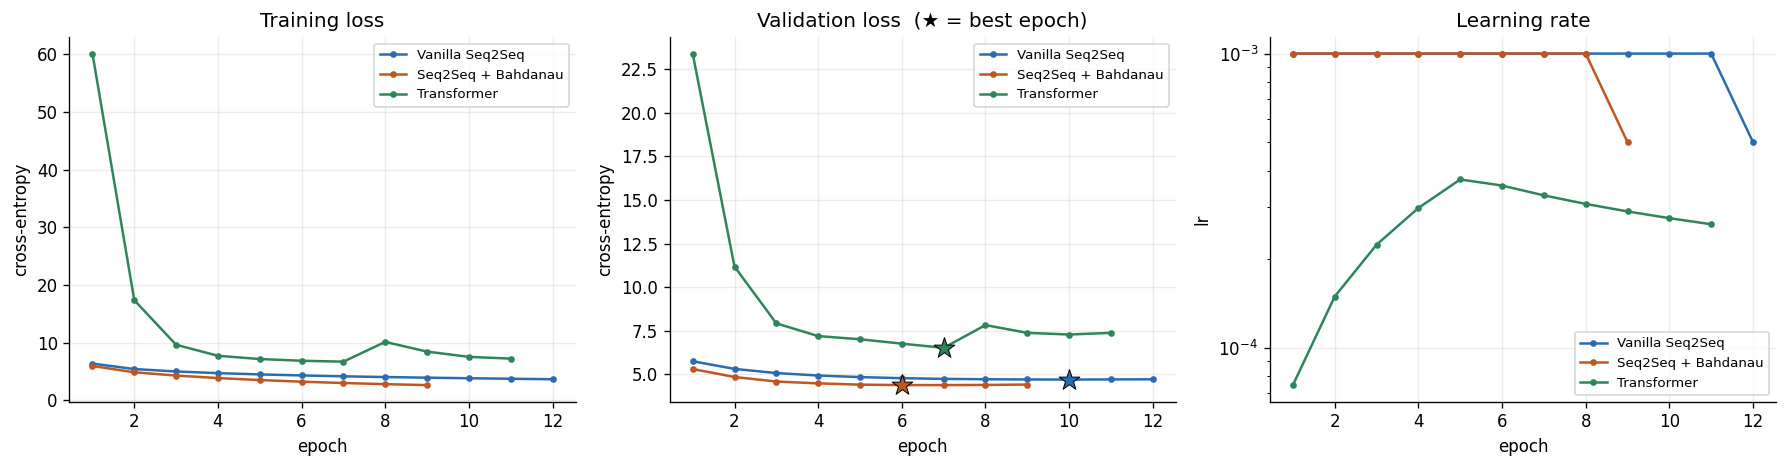

             model  best epoch  best val loss  best val ppl  final train loss  total min
   Vanilla Seq2Seq          10         4.6957        109.48            3.6672       51.2
Seq2Seq + Bahdanau           6         4.3803         79.86            2.6522      120.8
       Transformer           7         6.5154        675.49            7.2415       56.3


In [55]:
HISTORIES = {
    "Vanilla Seq2Seq":      load_json(D_MODELS / "vanilla_history.json", {}) or {},
    "Seq2Seq + Bahdanau":   load_json(D_MODELS / "attention_history.json", {}) or {},
    "Transformer":          load_json(D_MODELS / "transformer_history.json", {}) or {},
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colours = {"Vanilla Seq2Seq": "#2b6cb0", "Seq2Seq + Bahdanau": "#c05621", "Transformer": "#2f855a"}

for label, hist in HISTORIES.items():
    if not hist.get("val_loss"):
        continue
    ep = range(1, len(hist["val_loss"]) + 1)
    axes[0].plot(ep, hist["train_loss"], marker="o", ms=3, label=label, color=colours[label])
    axes[1].plot(ep, hist["val_loss"], marker="o", ms=3, label=label, color=colours[label])
    axes[2].plot(ep, hist["lr"], marker="o", ms=3, label=label, color=colours[label])
    best_ep = hist.get("best_epoch")
    if best_ep:
        axes[1].scatter([best_ep], [hist["best_val_loss"]], marker="*", s=170,
                        color=colours[label], zorder=5, edgecolor="black", linewidth=0.6)

axes[0].set(title="Training loss", xlabel="epoch", ylabel="cross-entropy")
axes[1].set(title="Validation loss  (★ = best epoch)", xlabel="epoch", ylabel="cross-entropy")
axes[2].set(title="Learning rate", xlabel="epoch", ylabel="lr", yscale="log")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(D_FIGS / "02_training_curves.png", bbox_inches="tight")
plt.show()

summary_rows = []
for label, hist in HISTORIES.items():
    if hist.get("val_loss"):
        summary_rows.append({
            "model": label,
            "best epoch": hist.get("best_epoch"),
            "best val loss": round(hist.get("best_val_loss", float("nan")), 4),
            "best val ppl": round(math.exp(min(20, hist.get("best_val_loss", 20))), 2),
            "final train loss": round(hist["train_loss"][-1], 4),
            "total min": round(sum(hist["epoch_seconds"]) / 60, 1),
        })
if summary_rows:
    print(pd.DataFrame(summary_rows).to_string(index=False))

---
## Stage 7 — Evaluation and analysis

The official test set is decoded with **both** greedy and beam search. Three metrics are
reported:

- **BLEU** — the standard n-gram metric; computed with `intl` tokenisation, which is
  multilingual-safe (the default `13a` tokeniser is English-specific and inappropriate for
  Devanagari output).
- **chrF++** — character-level F-score with word order 2. Because Hindi is morphologically
  rich, a translation can be semantically correct while sharing few whole words with the
  reference; chrF++ is far more forgiving of that and is the metric to trust here.
- **TER** — translation edit rate (lower is better).

Beam search is run on the first `beam_eval_limit` test sentences and greedy on the full
`eval_limit`, so the two columns are not directly comparable — the greedy column is the
headline number and beam is the ablation.

#### 7.1 · Decode the test set with every model

In [56]:
RESULTS = load_json(D_RESULTS / "results.json", {}) or {}
RESULTS.setdefault("config", asdict(CFG))
RESULTS.setdefault("data", DATA_SUMMARY)
RESULTS.setdefault("tokenizer", TOKENIZER_SUMMARY)
RESULTS.setdefault("params", {k: count_parameters(v) for k, v in MODELS.items()})
RESULTS.setdefault("models", {})

EVAL_SRC  = [SRC_TOK.decode(SRC_TOK.encode_plain(t)) for t in TEST_EN[:CFG.eval_limit]]
EVAL_REF  = TEST_HI[:CFG.eval_limit]
BEAM_SRC  = EVAL_SRC[:CFG.beam_eval_limit]
BEAM_REF  = EVAL_REF[:CFG.beam_eval_limit]

log(f"greedy evaluation on {len(EVAL_SRC):,} sentences; "
    f"beam({CFG.beam_size}) on the first {len(BEAM_SRC):,}")

for key, model in MODELS.items():
    spec = SPECS[key]
    entry = RESULTS["models"].setdefault(spec.name, {})
    entry["params"] = count_parameters(model)
    entry["key"] = key

    hist = HISTORIES.get(spec.name, {})
    entry["best_epoch"] = hist.get("best_epoch")
    entry["best_val_loss"] = hist.get("best_val_loss")
    entry["train_loss_final"] = hist["train_loss"][-1] if hist.get("train_loss") else None

    log(f"  [{spec.name}] greedy decoding ...")
    t0 = time.time()
    hyps_greedy = translate_corpus(model, EVAL_SRC, SRC_TOK, TGT_TOK,
                                   method="greedy", max_len=CFG.max_decode_len)
    entry["greedy"] = corpus_metrics(hyps_greedy, EVAL_REF)
    entry["greedy_seconds"] = round(time.time() - t0, 1)
    log(f"  [{spec.name}] greedy -> BLEU {entry['greedy']['bleu']:.2f} "
        f"chrF++ {entry['greedy']['chrf++']:.2f} TER {entry['greedy']['ter']:.2f} "
        f"({entry['greedy_seconds']}s)")

    log(f"  [{spec.name}] beam decoding (k={CFG.beam_size}) ...")
    t0 = time.time()
    hyps_beam = translate_corpus(model, BEAM_SRC, SRC_TOK, TGT_TOK,
                                 method="beam", max_len=CFG.max_decode_len,
                                 beam_size=CFG.beam_size, length_alpha=CFG.length_alpha)
    entry["beam"] = corpus_metrics(hyps_beam, BEAM_REF)
    entry["beam_seconds"] = round(time.time() - t0, 1)
    log(f"  [{spec.name}] beam   -> BLEU {entry['beam']['bleu']:.2f} "
        f"chrF++ {entry['beam']['chrf++']:.2f} TER {entry['beam']['ter']:.2f} "
        f"({entry['beam_seconds']}s)")

    entry["examples"] = [
        {"source": EVAL_SRC[i], "reference": EVAL_REF[i], "greedy": hyps_greedy[i]}
        for i in range(min(25, len(EVAL_SRC)))
    ]
    save_json(hyps_greedy, D_RESULTS / f"hyp_greedy_{key}.json")
    save_json(hyps_beam,   D_RESULTS / f"hyp_beam_{key}.json")
    save_json(RESULTS, D_RESULTS / "results.json")

save_json(RESULTS, D_RESULTS / "results.json")
print("\nevaluation complete ->", D_RESULTS / "results.json")

[11:06:10] greedy evaluation on 2,505 sentences; beam(5) on the first 1,000
[11:06:10]   [Vanilla Seq2Seq] greedy decoding ...
[11:06:11]     greedy: 10/40 batches
[11:06:12]     greedy: 20/40 batches
[11:06:13]     greedy: 30/40 batches
[11:06:15]     greedy: 40/40 batches
[11:06:37]   [Vanilla Seq2Seq] greedy -> BLEU 1.33 chrF++ 14.80 TER 100.81 (27.1s)
[11:06:37]   [Vanilla Seq2Seq] beam decoding (k=5) ...
[11:06:46]     beam: 10/16 batches
[11:06:52]     beam: 16/16 batches
[11:06:57]   [Vanilla Seq2Seq] beam   -> BLEU 1.52 chrF++ 13.65 TER 96.36 (20.3s)
[11:06:57]   [Seq2Seq + Bahdanau] greedy decoding ...
[11:07:03]     greedy: 10/40 batches
[11:07:10]     greedy: 20/40 batches
[11:07:17]     greedy: 30/40 batches
[11:07:23]     greedy: 40/40 batches
[11:07:47]   [Seq2Seq + Bahdanau] greedy -> BLEU 2.67 chrF++ 18.56 TER 98.66 (49.9s)
[11:07:47]   [Seq2Seq + Bahdanau] beam decoding (k=5) ...
[11:08:21]     beam: 10/16 batches
[11:08:41]     beam: 16/16 batches
[11:08:48]   [Seq2Se

#### 7.2 · The headline results table

In [57]:
def results_table(results: Dict) -> pd.DataFrame:
    rows = []
    for name, entry in results.get("models", {}).items():
        g, b = entry.get("greedy", {}), entry.get("beam", {})
        rows.append({
            "model": name,
            "params (M)": round(entry.get("params", 0) / 1e6, 2),
            "best val loss": round(entry.get("best_val_loss") or float("nan"), 4),
            "BLEU (greedy)": g.get("bleu"),
            "chrF++ (greedy)": g.get("chrf++"),
            "TER (greedy)": g.get("ter"),
            f"BLEU (beam k={CFG.beam_size})": b.get("bleu"),
            "chrF++ (beam)": b.get("chrf++"),
        })
    df = pd.DataFrame(rows)
    if not df.empty:
        df = df.sort_values("chrF++ (greedy)", ascending=False).reset_index(drop=True)
    return df

results_df = results_table(RESULTS)
print("=" * 100)
print(f"  TEST-SET RESULTS   (greedy n={len(EVAL_SRC):,} | "
      f"beam k={CFG.beam_size} n={len(BEAM_SRC):,})")
print("=" * 100)
print(results_df.to_string(index=False))
print("=" * 100)

if len(results_df) >= 2:
    best = results_df.iloc[0]
    worst = results_df.iloc[-1]
    print(f"\nBest chrF++  : {best['model']}  ({best['chrF++ (greedy)']:.2f})")
    print(f"Worst chrF++ : {worst['model']}  ({worst['chrF++ (greedy)']:.2f})")
    print(f"Spread       : {best['chrF++ (greedy)'] - worst['chrF++ (greedy)']:.2f} chrF++ points")

if not results_df.empty:
    results_df.to_csv(D_RESULTS / "metrics.csv", index=False)
    print("\nsaved ->", D_RESULTS / "metrics.csv")

  TEST-SET RESULTS   (greedy n=2,505 | beam k=5 n=1,000)
             model  params (M)  best val loss  BLEU (greedy)  chrF++ (greedy)  TER (greedy)  BLEU (beam k=5)  chrF++ (beam)
Seq2Seq + Bahdanau       94.80         4.3803          2.665           18.560        98.656            3.307         17.929
   Vanilla Seq2Seq       43.15         4.6957          1.334           14.796       100.814            1.524         13.649
       Transformer       62.23         6.5154          0.427            7.911       213.607            0.941          9.094

Best chrF++  : Seq2Seq + Bahdanau  (18.56)
Worst chrF++ : Transformer  (7.91)
Spread       : 10.65 chrF++ points

saved -> /kaggle/working/EnHi_NMT_Study/results/metrics.csv


#### 7.3 · Does attention help more on long sentences?

chrF++ by source sentence length (words)
model         Seq2Seq + Bahdanau  Transformer  Vanilla Seq2Seq
source words                                                  
0-10                       16.77         8.55            12.81
10-20                      18.54         7.71            14.14
20-30                      18.38         8.05            14.96
30-200                     19.12         7.88            15.65


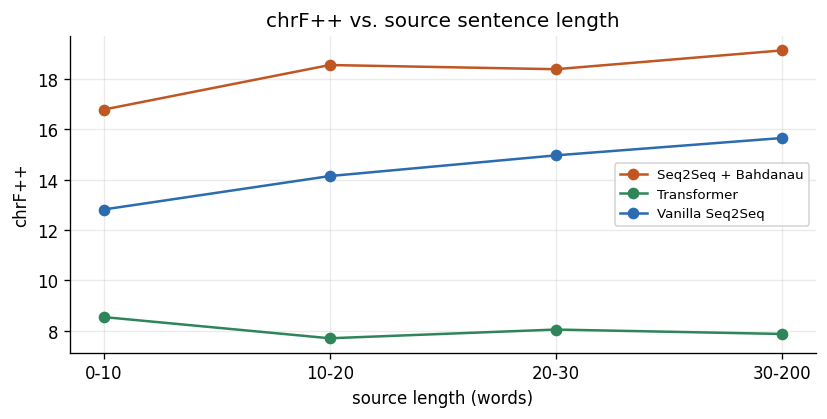


Interpretation: a fixed-vector model should degrade fastest as length grows.


In [58]:
def length_bucket_analysis(results, buckets=((0, 10), (10, 20), (20, 30), (30, 200))):
    out = []
    for name, entry in results.get("models", {}).items():
        key = entry.get("key")
        hyps = load_json(D_RESULTS / f"hyp_greedy_{key}.json", None)
        if not hyps:
            continue
        lens = [len(s.split()) for s in EVAL_SRC[:len(hyps)]]
        for lo, hi in buckets:
            idx = [i for i, L in enumerate(lens) if lo <= L < hi]
            if len(idx) < 15:
                continue
            m = corpus_metrics([hyps[i] for i in idx], [EVAL_REF[i] for i in idx])
            out.append({"model": name, "source words": f"{lo}-{hi}",
                        "n": len(idx), "chrF++": m["chrf++"], "BLEU": m["bleu"]})
    return pd.DataFrame(out)

bucket_df = length_bucket_analysis(RESULTS)
if not bucket_df.empty:
    pivot = bucket_df.pivot(index="source words", columns="model", values="chrF++")
    order = [f"{lo}-{hi}" for lo, hi in ((0, 10), (10, 20), (20, 30), (30, 200))]
    pivot = pivot.reindex([o for o in order if o in pivot.index])
    print("chrF++ by source sentence length (words)")
    print(pivot.round(2).to_string())
    bucket_df.to_csv(D_RESULTS / "metrics_by_length.csv", index=False)

    fig, ax = plt.subplots(figsize=(7, 3.6))
    for col in pivot.columns:
        ax.plot(pivot.index, pivot[col], marker="o", label=col, color=colours.get(col))
    ax.set(title="chrF++ vs. source sentence length", xlabel="source length (words)", ylabel="chrF++")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(D_FIGS / "03_chrf_by_length.png", bbox_inches="tight")
    plt.show()

    print("\nInterpretation: a fixed-vector model should degrade fastest as length grows.")

#### 7.4 · Error analysis — where the models actually fail

In [59]:
def error_examples(results, key, n=12, min_chrf_gap=True):
    hyps = load_json(D_RESULTS / f"hyp_greedy_{key}.json", None)
    if not hyps:
        return []
    scored = []
    for i, (src, ref, hyp) in enumerate(zip(EVAL_SRC[:len(hyps)], EVAL_REF[:len(hyps)], hyps)):
        chrf = sacrebleu.sentence_chrf(hyp or ".", [ref or "."]).score
        scored.append((chrf, i, src, ref, hyp))
    scored.sort(key=lambda x: x[0])
    return scored[:n], scored[-min(5, n):]

print("=" * 110)
print("  WORST TRANSLATIONS PER MODEL  (ranked by sentence chrF)")
print("=" * 110)
for name, entry in RESULTS.get("models", {}).items():
    key = entry.get("key")
    res = error_examples(RESULTS, key, n=4)
    if not res:
        continue
    worst, best = res
    print(f"\n### {name}")
    for chrf, i, src, ref, hyp in worst:
        print(f"  chrF {chrf:5.1f} | EN : {src[:95]}")
        print(f"              | REF: {ref[:95]}")
        print(f"              | HYP: {hyp[:95]}")
        print()

print("=" * 110)
print("  OUTPUT LENGTH BEHAVIOUR")
print("=" * 110)
len_rows = []
for name, entry in RESULTS.get("models", {}).items():
    hyps = load_json(D_RESULTS / f"hyp_greedy_{entry.get('key')}.json", None)
    if not hyps:
        continue
    hl = np.array([len(h.split()) for h in hyps])
    rl = np.array([len(r.split()) for r in EVAL_REF[:len(hyps)]])
    len_rows.append({
        "model": name,
        "mean hyp words": round(float(hl.mean()), 1),
        "mean ref words": round(float(rl.mean()), 1),
        "ratio": round(float(hl.mean() / max(rl.mean(), 1e-9)), 3),
        "empty outputs": int((hl == 0).sum()),
        "max hyp words": int(hl.max()),
    })
len_df = pd.DataFrame(len_rows)
print(len_df.to_string(index=False))
print("\nA ratio near 1.0 means the model is not systematically over- or under-generating.")

  WORST TRANSLATIONS PER MODEL  (ranked by sentence chrF)

### Vanilla Seq2Seq
  chrF   1.7 | EN : In 2011 Google placed an initial $900 million bid for Nortel's patents.
              | REF: वर्ष 2011 में गूगल ने नॉरटेल पेटेन्ट्स के लिए 900 मिलियन डॉलर की आरंभिक बोली लगाई थी।
              | HYP: 00000000000000000000000असल.

  chrF   1.9 | EN : They and 32 other men were later jailed after police seized heroin and cocaine worth £1.5millio
              | REF: उसमें 32 अन्य व्यक्ति थे, जिन्हें पुलिस द्वारा कई छापों के दौरान 1.5 मिलियन पाउंड कीमत की हीरोई
              | HYP: वे 32000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000

  chrF   2.0 | EN : Australian woman appeals Thai jail time
              | REF: ऑस्ट्रेलियाई महिला ने थाई कारावास अवधि के विरूद्ध अपील किया
              | HYP: समय समय समय

  chrF   2.2 | EN : The fans of German-American Model Heidi Klum were shocked at what she had done.
              | REF: जर्मन-अमेरिकन मॉडल हीदी क

#### 7.5 · Attention alignment heatmap (Model ②)

SOURCE : The formerly super secretive NSA, once nicknamed No Such Agency, has found itself in very public light, and amid vicious criticism, in past months following a stream of revelations about is vast foreign and domestic surv
REF    : भूतपूर्व अत्यधिक रहस्यपूर्ण एन.एस.ए., जिसे कभी "ऐसी कोई एजेन्सी नहीं" का नाम दिया गया था, पिछले महीनों में बहुत अधिक मात्रा में विदेशी और घरेलू जासूसी कार्यक्रमों की घटनाओं के सामने आने से आम लोगों के बीच में चर्चा तथा क
HYPOTH : इसके बाद, 2003 में एक बार फिर न केवल शुद्ध आमदनी के लिए और अधिक गहराई में, और कई महीनों में, जिसमें एक और अधिक व्यापक रूप से घिरा हुआ है और इसके बाद भी, ‘नियोजन’ और 1950 से अधिक लोग और प्रशांत द्वीप द्वारा 1500 ई. ई. ई. 
attention matrix: (82, 78)  (generated steps x source tokens)


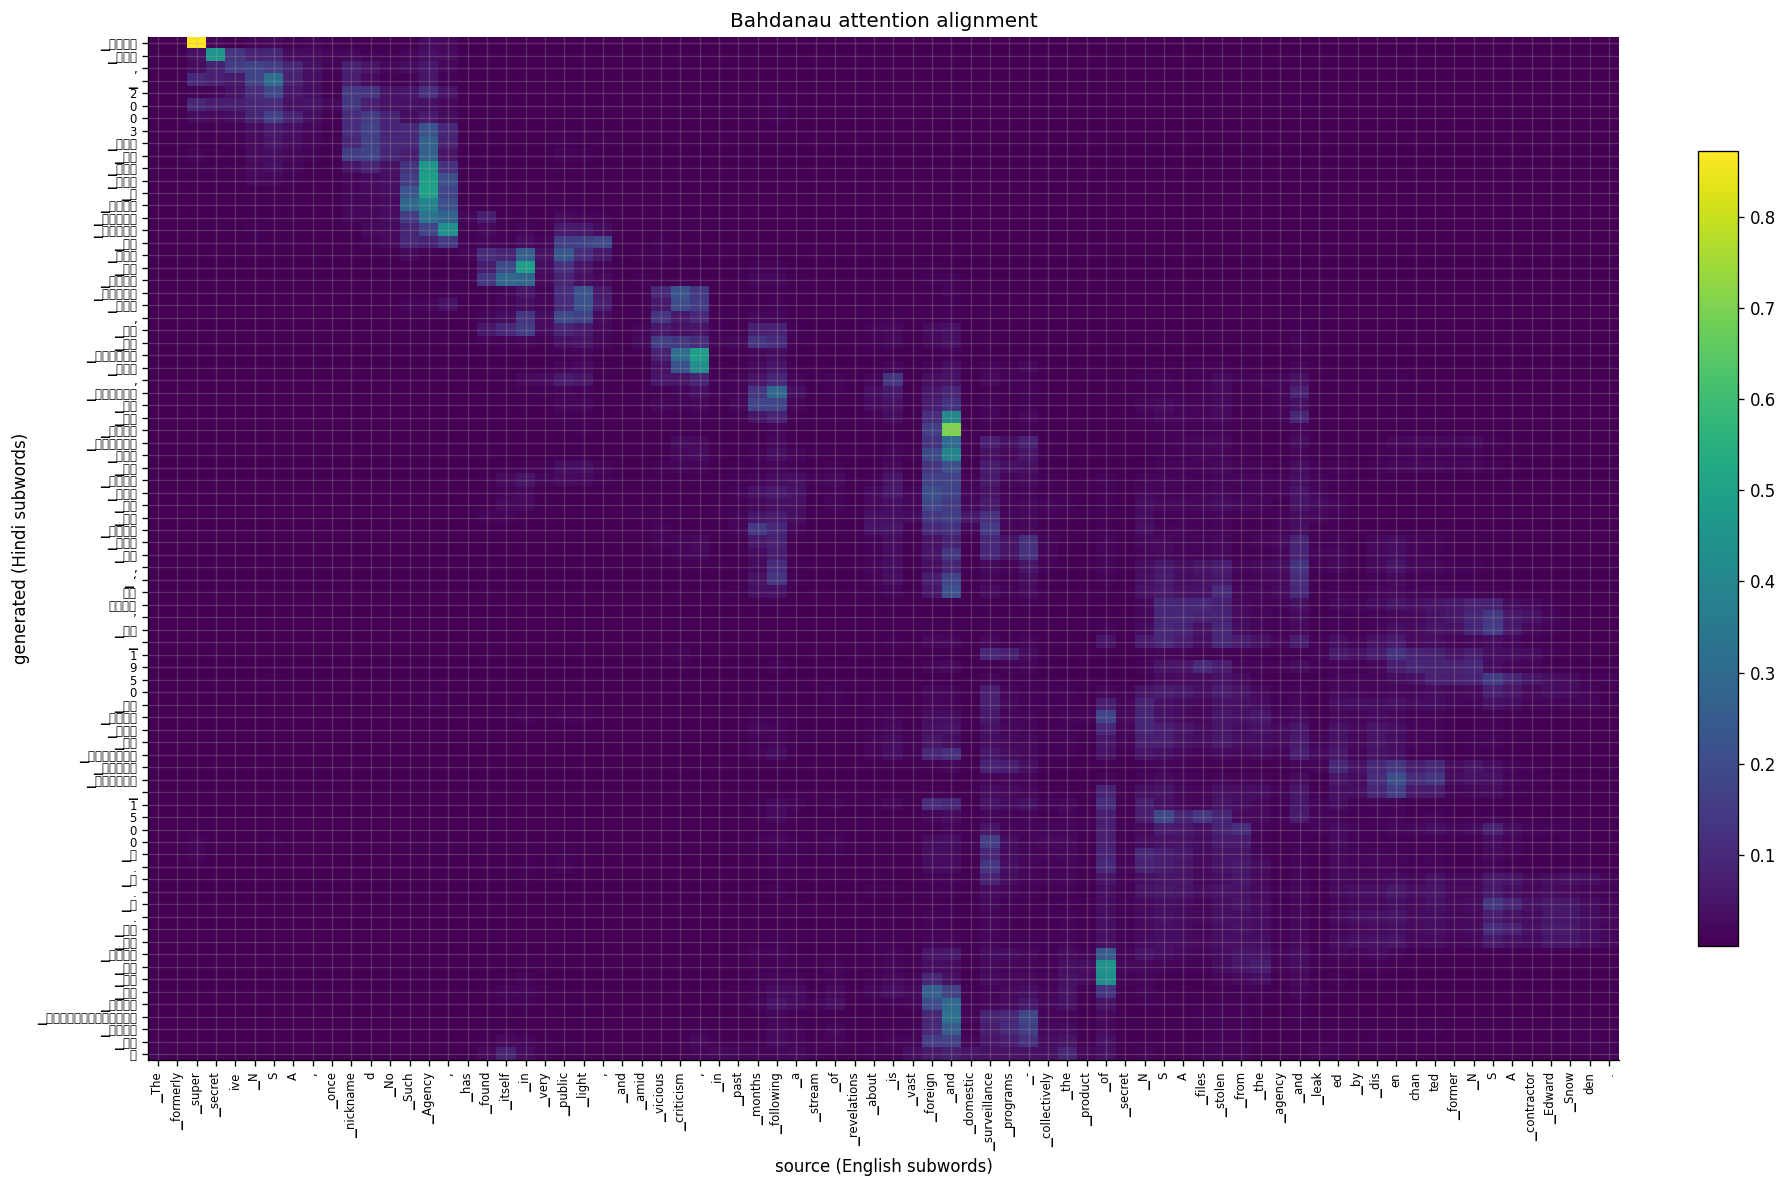


A healthy alignment is roughly monotone (close to the diagonal),
with a clear diagonal band for content words and diffuse mass for function words.


In [60]:
attn_model = MODELS["attention"]
attn_model.eval()

_candidates = sorted(range(min(300, len(EVAL_SRC))), key=lambda i: len(EVAL_SRC[i].split()))
demo_idx = int(_candidates[-1])
src_sentence = EVAL_SRC[demo_idx]
ref_sentence = EVAL_REF[demo_idx]

hyp_sentence, hyp_ids, attn = attn_model.translate_with_attention(
    src_sentence, SRC_TOK, TGT_TOK, max_len=CFG.max_decode_len)

n_src = attn.shape[1] if attn.size else 0
n_tgt = attn.shape[0] if attn.size else 0
src_pieces = SRC_TOK.pieces(src_sentence)[:n_src]
tgt_pieces = [TGT_TOK.sp.id_to_piece(i) for i in hyp_ids[:n_tgt]]

print("SOURCE :", src_sentence[:220])
print("REF    :", ref_sentence[:220])
print("HYPOTH :", hyp_sentence[:220])
print(f"attention matrix: {attn.shape}  (generated steps x source tokens)")

if attn.size and src_pieces and tgt_pieces:
    fig, ax = plt.subplots(figsize=(min(15, 0.34 * len(src_pieces) + 3.5),
                                    min(10, 0.34 * len(tgt_pieces) + 2.5)))
    im = ax.imshow(attn[:len(tgt_pieces), :len(src_pieces)], cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(src_pieces)))
    ax.set_xticklabels(src_pieces, rotation=90, fontsize=7)
    ax.set_yticks(range(len(tgt_pieces)))
    ax.set_yticklabels(tgt_pieces, fontsize=7)
    ax.set(xlabel="source (English subwords)", ylabel="generated (Hindi subwords)",
           title="Bahdanau attention alignment")
    plt.colorbar(im, ax=ax, fraction=0.025)
    plt.tight_layout()
    plt.savefig(D_FIGS / "04_attention_heatmap.png", bbox_inches="tight")
    plt.show()
    print("\nA healthy alignment is roughly monotone (close to the diagonal),")
    print("with a clear diagonal band for content words and diffuse mass for function words.")
else:
    print("could not build a heatmap for this sample")

#### 7.6 · Summary figures

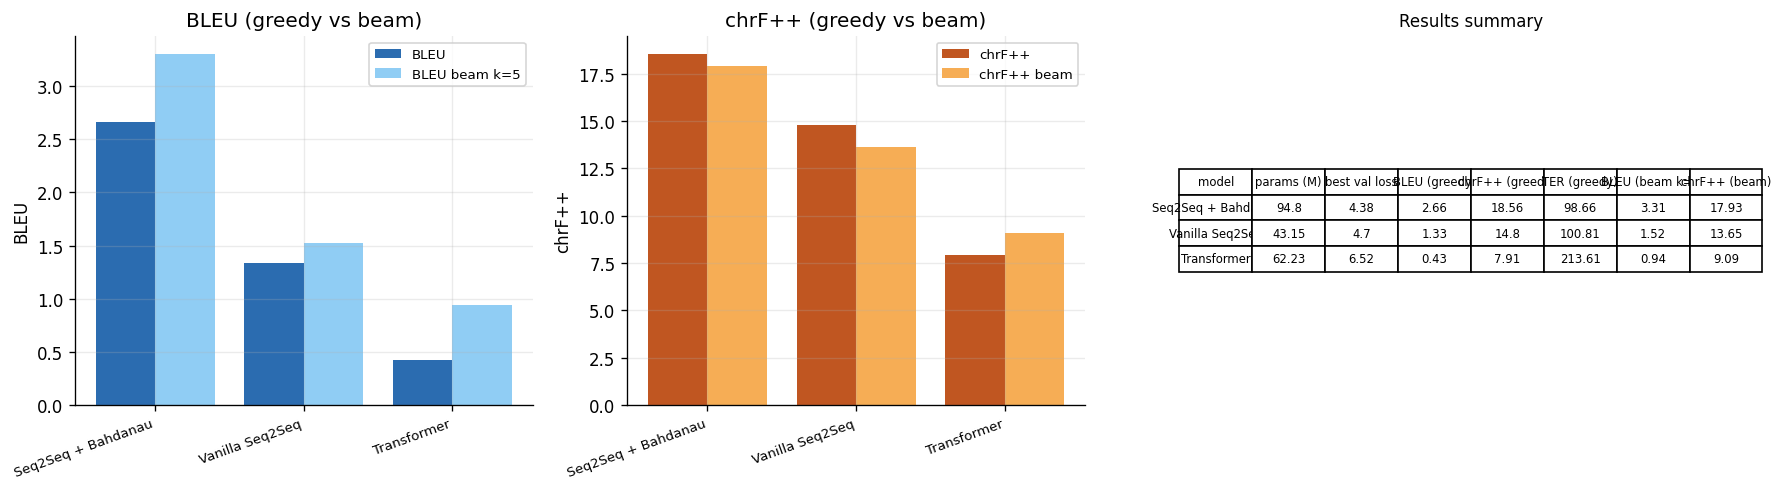

  SIDE-BY-SIDE TRANSLATIONS

[0] EN  : A black box in your car?
    REF : आपकी कार में ब्लैक बॉक्स?
    Vanilla Seq2Seq     : अपने आप अपने बच्चे में से कोई भी नहीं देख सकता है?
    Seq2Seq + Bahdanau  : आपके पार्सल में एक रोगी का चयन किया गया?
    Transformer         : आपके आपके एक-

[1] EN  : As America's road planners struggle to find the cash to mend a crumbling highway system, many are beginning to see a solution in a little black box that fits neatly by the dashboard of your car.
    REF : जबकि अमेरिका के सड़क योजनाकार, ध्वस्त होते हुए हाईवे सिस्टम को सुधारने के लिए धन की कमी से जूझ रहे हैं, वहीं बहुत-से लोग इसका समाधान छोटे से ब्लैक बॉक्स में देख रहे हैं, जो आपकी कार के डैशबोर्ड पर सफ़ाई से फिट हो जाता है।
    Vanilla Seq2Seq     : 1950 के दौरान, जब तक कि बच्चे के कुछ लोग अपने बच्चे के साथ-साथ अपने-आपको से एक डायरी के साथ-साथ एक दर्जन में परिवर्तित करने के लिए, तो एक बार फिर से एक बार फिर से ही अपने उदर को पूरा करने के लिए, एक बार फिर से दाँतों का प्रयास किया जा सकता है।
    Seq2

In [61]:
fig = plt.figure(figsize=(15, 4.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.1, 1.4])

if not results_df.empty:
    ax = fig.add_subplot(gs[0, 0])
    x = np.arange(len(results_df))
    ax.bar(x - 0.2, results_df["BLEU (greedy)"], 0.4, label="BLEU", color="#2b6cb0")
    ax.bar(x + 0.2, results_df[f"BLEU (beam k={CFG.beam_size})"], 0.4,
           label=f"BLEU beam k={CFG.beam_size}", color="#90cdf4")
    ax.set_xticks(x)
    ax.set_xticklabels(results_df["model"], rotation=20, ha="right", fontsize=8)
    ax.set(title="BLEU (greedy vs beam)", ylabel="BLEU")
    ax.legend(fontsize=8)

    ax = fig.add_subplot(gs[0, 1])
    ax.bar(x - 0.2, results_df["chrF++ (greedy)"], 0.4, label="chrF++", color="#c05621")
    ax.bar(x + 0.2, results_df["chrF++ (beam)"], 0.4, label="chrF++ beam", color="#f6ad55")
    ax.set_xticks(x)
    ax.set_xticklabels(results_df["model"], rotation=20, ha="right", fontsize=8)
    ax.set(title="chrF++ (greedy vs beam)", ylabel="chrF++")
    ax.legend(fontsize=8)

    ax = fig.add_subplot(gs[0, 2])
    ax.axis("off")
    table = ax.table(cellText=results_df.round(2).values,
                     colLabels=results_df.columns, loc="center", cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(7)
    table.scale(1, 1.35)
    ax.set_title("Results summary", fontsize=10)

plt.tight_layout()
plt.savefig(D_FIGS / "05_results_summary.png", bbox_inches="tight")
plt.show()

print("=" * 110)
print("  SIDE-BY-SIDE TRANSLATIONS")
print("=" * 110)
n_show = 6
for i in range(min(n_show, len(EVAL_SRC))):
    print(f"\n[{i}] EN  : {EVAL_SRC[i]}")
    print(f"    REF : {EVAL_REF[i]}")
    for name, entry in RESULTS.get("models", {}).items():
        hyps = load_json(D_RESULTS / f"hyp_greedy_{entry.get('key')}.json", None)
        if hyps and i < len(hyps):
            print(f"    {name[:20]:<20}: {hyps[i]}")

---
## Stage 8 — Interactive demonstration

Type an English sentence and translate it with any of the three models.

#### 8.1 · Translate your own sentence

In [62]:
def translate(text: str, model_key: str = "transformer", method: str = "beam",
              beam_size: Optional[int] = None) -> str:
    model = MODELS[model_key]
    model.eval()
    device = next(model.parameters()).device
    ids = SRC_TOK.encode(text)
    src = torch.tensor([ids], dtype=torch.long, device=device)
    src_len = torch.tensor([len(ids)], dtype=torch.long, device=device)

    if method == "greedy":
        gen = greedy_decode(model, src, src_len, BOS_ID, EOS_ID, CFG.max_decode_len)[0].tolist()
        if EOS_ID in gen:
            gen = gen[:gen.index(EOS_ID)]
        return TGT_TOK.decode(gen)

    outs = beam_search(model, src, src_len, BOS_ID, EOS_ID, PAD_ID,
                       CFG.max_decode_len, beam_size or CFG.beam_size, CFG.length_alpha)
    return TGT_TOK.decode(outs[0])

DEMO_SENTENCES = [
    "The committee approved the new proposal after a long discussion.",
    "Machine translation has improved dramatically in recent years.",
    "She said that the results would be published next month.",
]

for s in DEMO_SENTENCES:
    print("EN :", s)
    for k, spec in SPECS.items():
        print(f"  {spec.name[:22]:<22}: {translate(s, k, method='beam')}")
    print()

if sys.stdin.isatty():
    try:
        user_text = input("\nType an English sentence to translate (or press Enter to skip): ").strip()
        if user_text:
            for k, spec in SPECS.items():
                print(f"{spec.name[:22]:<22}: {translate(user_text, k, method='beam')}")
    except Exception:
        pass
else:
    print("\n(non-interactive run - skipping the free-text prompt)")

EN : The committee approved the new proposal after a long discussion.
  Vanilla Seq2Seq       : नई दिल्ली में नई दिल्ली के बारे में जानकारी दी गई थी।
  Seq2Seq + Bahdanau    : समिति ने नई बैठक के बाद नया प्रस्ताव रखा।
  Transformer           : नए नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई नई तैयार हो गई।

EN : Machine translation has improved dramatically in recent years.
  Vanilla Seq2Seq       : उत्तर प्रदेश में 70 वर्षों के दौरान प्रतिबद्ध है।
  Seq2Seq + Bahdanau    : हाल ही वर्षों में हाल की प्रगति हुई है।
  Transformer           : वर्षों में एक वर्षों में वर्ष की गई है।

EN : She said that the results would be published next month.
  Vanilla Seq2Seq       : उन्होंने कहा कि ‘मेक’ के रूप में कहा जाएगा।
  Seq2Seq + Bahdanau    : उन्होंने कहा कि यह अगले महीने होगा।
  Transformer           :

---
## Stage 9 — Summary and next steps

### What to do next

1. **Run it once with `PRESET = "smoke"`** to confirm the pipeline works end to end in a
   few minutes before committing to the full run.
2. **Switch to `"balanced"`** (or `"full"` overnight) and run all cells.
3. Collect the artefacts from `<Drive>/EnHi_NMT_Study/`:
   - `results/metrics.csv` and `results/results.json` — the numbers, ready for the LaTeX report
   - `figures/*.png` — every chart, saved at print resolution

### Things you could add later

| Idea | Why it would strengthen the study |
|---|---|
| Multi-seed sweep (3 seeds) | attaches error bars to the ranking |
| COMET metric | a learned metric that correlates better with human judgement |
| Pre-trained baseline (`Helsinki-NLP/opus-mt-en-hi` or NLLB) | gives an upper-bound reference point |
| BPE vs Unigram vs word-level ablation | isolates the tokenisation contribution |
| BERTScore | semantic similarity, complements surface metrics |
| Learning-curve study (10 K → 400 K pairs) | shows how much data each architecture needs |

### Why tokenisation is the decisive lever

The single highest-leverage decision in this notebook is **subword tokenisation**. Stage 2
measures the word-level Hindi out-of-vocabulary rate on the test set, and then the subword
`<unk>` rate on the same data; the drop is typically two to three orders of magnitude.

No amount of additional training, capacity or decoding could compensate for a vocabulary
that cannot represent the target language.

#### 9.1 · Final artefact manifest

In [63]:
def _bundle():
    out = {
        "root": str(ROOT),
        "metrics_csv": str(D_RESULTS / "metrics.csv"),
        "results_json": str(D_RESULTS / "results.json"),
        "figures": sorted(p.name for p in D_FIGS.glob("*.png")),
        "checkpoints": sorted(p.name for p in D_MODELS.glob("*.pt")),
        "tokenizers": sorted(p.name for p in D_DATA.glob("*.model")),
    }
    return out

manifest = _bundle()
print(json.dumps(manifest, indent=2))

zip_base = str(ROOT.parent / f"EnHi_NMT_Study_{CFG.preset}")
try:
    shutil.make_archive(zip_base, "zip", root_dir=str(ROOT))
    print("\nbundle ->", zip_base + ".zip")
except Exception as exc:
    print("zip failed:", exc)

log("run complete")
print("\nDONE. All artefacts are under:", ROOT)

{
  "root": "/kaggle/working/EnHi_NMT_Study",
  "metrics_csv": "/kaggle/working/EnHi_NMT_Study/results/metrics.csv",
  "results_json": "/kaggle/working/EnHi_NMT_Study/results/results.json",
  "figures": [
    "01_length_distribution.png",
    "02_training_curves.png",
    "03_chrf_by_length.png",
    "04_attention_heatmap.png",
    "05_results_summary.png"
  ],
  "checkpoints": [
    "attention.pt",
    "transformer.pt",
    "vanilla.pt"
  ],
  "tokenizers": [
    "sp_en.model",
    "sp_hi.model"
  ]
}

bundle -> /kaggle/working/EnHi_NMT_Study_balanced.zip
[11:24:23] run complete

DONE. All artefacts are under: /kaggle/working/EnHi_NMT_Study
